# BTL02 — Nhận dạng cảm xúc khuôn mặt trên FER2013 bằng CNN

**Nhóm SGU26 — Chuyên đề Học sâu**

- Sinh viên thực hiện: Huỳnh Nhật Minh — 3123580025
- Nhiệm vụ: huấn luyện CNN trên bộ dữ liệu Kaggle FER2013, khảo sát nhiều cấu hình siêu tham số, trực quan bộ lọc tích chập và phân tích kết quả.

Notebook này là **mã nguồn duy nhất** của bài tập và được tổ chức theo đúng trình tự thực nghiệm:

1. Cấu hình môi trường và đường dẫn.
2. Nạp, khảo sát dữ liệu FER2013.
3. Tiền xử lý và tăng cường dữ liệu.
4. Định nghĩa các kiến trúc CNN.
5. Quy trình huấn luyện và đánh giá dùng chung.
6. **Nhóm A** — so sánh kiến trúc Small / Medium / Large.
7. **Nhóm B** — khảo sát kỹ thuật huấn luyện: augmentation, BatchNorm, kết hợp cả hai.
8. **Nhóm C** — khảo sát optimizer, hàm kích hoạt và learning rate.
9. Tổng hợp, chọn mô hình cuối theo validation và huấn luyện lại.
10. Đánh giá trên tập PrivateTest: confusion matrix, precision/recall/F1, ca đúng/sai.
11. Trực quan bộ lọc tích chập và feature map.
12. Kết luận, phụ lục nhật ký thực nghiệm.

> **Cách chạy:** đặt `fer2013.csv` trong thư mục `data/` (hoặc tải bằng `kaggle datasets download -d deadskull7/fer2013 -p data --unzip`), sau đó chọn **Restart Kernel and Run All Cells**. Toàn bộ kết quả được ghi vào `outputs/`; nhật ký thực nghiệm được sinh ở `outputs/experiment_log.xlsx` (7 sheet).
>
> Với GPU 4 GB, toàn bộ 27 lượt huấn luyện ở nhóm A/B/C cộng mô hình cuối mất khoảng 2,5 giờ. Có thể giảm `SEEDS` hoặc `epochs` trong `BASE_CFG` để chạy nhanh hơn; mọi bảng và hình đều được sinh lại tự động.

## 1. Cấu hình môi trường

Notebook dùng PyTorch. Toàn bộ ảnh được đưa lên GPU một lần (48×48×1, khoảng 300 MB) để tránh nghẽn DataLoader trên Windows; augmentation được thực hiện theo lô ngay trên GPU. Cách làm này giữ code ngắn, chạy nhanh và vẫn bảo đảm mỗi ảnh có tham số biến đổi riêng.

Các thư mục đầu ra:

- `outputs/logs/` — log từng epoch của mỗi lượt chạy.
- `outputs/figures/` — toàn bộ hình dùng cho báo cáo và slide.
- `outputs/models/` — checkpoint mô hình cuối.
- `outputs/summary_runs.csv`, `outputs/summary_groups.csv` — bảng kết quả.
- `outputs/attempts_log.csv` — nhật ký mọi lượt chạy (OK/EARLY_STOP/CACHED/FAILED/DEBUG).
- `outputs/experiment_log.xlsx` — nhật ký thực nghiệm 7 sheet.

In [1]:
import json
import math
import random
import time
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 170,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titlesize": 11,
})

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "data" / "fer2013.csv").exists() and (ROOT / "BTL02" / "data" / "fer2013.csv").exists():
    ROOT = ROOT / "BTL02"

DATA_CSV = ROOT / "data" / "fer2013.csv"
assert DATA_CSV.exists(), f"Không tìm thấy {DATA_CSV}. Hãy đặt fer2013.csv trong thư mục data/."

OUT = ROOT / "outputs"
FIG = OUT / "figures"
for folder in ["data", "logs", "models", "figures", "cache"]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

CLASSES = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
SEEDS = [11, 22, 33]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cudnn.benchmark = True
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| thiết bị:", DEVICE)
print("Dataset:", DATA_CSV)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU
PyTorch: 2.11.0+cu128 | thiết bị: cuda
Dataset: C:\Users\ASUS\group_sgu26_deep_learning\BTL02\data\fer2013.csv


### 1.1. Cấu hình chung của thực nghiệm

Mọi cấu hình đều kế thừa `BASE_CFG`; mỗi nhóm chỉ thay đổi **một yếu tố** so với baseline (Medium, không augmentation, không BatchNorm, Adam 1e-3, ReLU, dropout 0,2). Cách bố trí này giúp quy kết chênh lệch hiệu năng cho đúng yếu tố đang khảo sát.

- Batch size 256, huấn luyện 20 epoch cho các lượt khảo sát, early stopping với patience 6 theo `val_loss`.
- Ba seed mô hình 11, 22, 33; kết quả báo cáo dạng trung bình ± độ lệch chuẩn.
- Chọn checkpoint tốt nhất theo validation (PublicTest), **không** dùng PrivateTest để chọn mô hình.
- PrivateTest chỉ dùng để báo cáo hiệu năng cuối cùng của từng lượt chạy.
- Mô hình cuối được chọn theo validation, huấn luyện lại 45 epoch với cosine learning-rate decay.

In [2]:
BASE_CFG = dict(
    batch_size=256,
    epochs=20,
    patience=6,
    optimizer="Adam",
    lr=1e-3,
    weight_decay=0.0,
    momentum=0.9,
    dropout=0.2,
    activation="relu",
    batchnorm=False,
    augment=False,
    label_smoothing=0.0,
    class_weight=False,
    cosine=False,
)

ARCHS = {
    "small": dict(widths=(32, 64, 128), convs=(2, 2, 2), fc=512),
    "medium": dict(widths=(64, 128, 256), convs=(3, 3, 3), fc=512),
    "large": dict(widths=(64, 128, 256, 512), convs=(2, 2, 2, 2), fc=512),
}


def make_cfg(arch="medium", **overrides):
    cfg = dict(BASE_CFG)
    cfg.update(ARCHS[arch])
    cfg["arch"] = arch
    cfg.update(overrides)
    return cfg


RUNS_A = [
    ("A1", "Small: 2-2-2 conv, 32-64-128", make_cfg("small")),
    ("A2", "Medium: 3-3-3 conv, 64-128-256", make_cfg("medium")),
    ("A3", "Large: 2-2-2-2 conv, 64-128-256-512", make_cfg("large")),
]
RUNS_B = [
    ("B1", "Medium + augmentation", make_cfg("medium", augment=True)),
    ("B2", "Medium + BatchNorm", make_cfg("medium", batchnorm=True)),
    ("B3", "Medium + augmentation + BatchNorm", make_cfg("medium", augment=True, batchnorm=True)),
]
RUNS_C = [
    ("C1", "SGD momentum 0.9, lr=0.01", make_cfg("medium", optimizer="SGD", lr=0.01, momentum=0.9)),
    ("C2", "LeakyReLU (0.1)", make_cfg("medium", activation="leakyrelu")),
    ("C3", "Adam, lr=5e-4", make_cfg("medium", lr=5e-4)),
]

RUN_CONFIGS = {rid: cfg for rid, _, cfg in RUNS_A + RUNS_B + RUNS_C}

pd.DataFrame([
    {"run": rid, "mô tả": label,
     "optimizer": cfg["optimizer"], "lr": cfg["lr"], "activation": cfg["activation"],
     "augment": cfg["augment"], "batchnorm": cfg["batchnorm"], "dropout": cfg["dropout"]}
    for rid, label, cfg in RUNS_A + RUNS_B + RUNS_C
])

,run,mô tả,optimizer,lr,activation,augment,batchnorm,dropout
0,A1,"Small: 2-2-2 conv, 32-64-128",Adam,0.0010,relu,False,False,0.2
1,A2,"Medium: 3-3-3 conv, 64-128-256",Adam,0.0010,relu,False,False,0.2
2,A3,"Large: 2-2-2-2 conv, 64-128-256-512",Adam,0.0010,relu,False,False,0.2
3,B1,Medium + augmentation,Adam,0.0010,relu,True,False,0.2
4,B2,Medium + BatchNorm,Adam,0.0010,relu,False,True,0.2
5,B3,Medium + augmentation + BatchNorm,Adam,0.0010,relu,True,True,0.2
6,C1,"SGD momentum 0.9, lr=0.01",SGD,0.0100,relu,False,False,0.2
7,C2,LeakyReLU (0.1),Adam,0.0010,leakyrelu,False,False,0.2
8,C3,"Adam, lr=5e-4",Adam,0.0005,relu,False,False,0.2


## 2. Dữ liệu FER2013

Bộ dữ liệu gồm 35.887 ảnh xám 48×48, chia sẵn theo cột `Usage`:

- `Training`: 28.709 ảnh — huấn luyện.
- `PublicTest`: 3.589 ảnh — validation, dùng để chọn checkpoint và chọn cấu hình.
- `PrivateTest`: 3.589 ảnh — kiểm thử cuối cùng.

Nhãn theo đúng quy ước của thử thách Kaggle: 0 Angry, 1 Disgust, 2 Fear, 3 Happy, 4 Sad, 5 Surprise, 6 Neutral. Mỗi ảnh được lưu dưới dạng chuỗi 2.304 giá trị pixel trong `fer2013.csv`; notebook chuyển thành mảng `uint8` và cache lại thành `outputs/data/fer2013.npz` để lần chạy sau nhanh hơn.

In [3]:
cache = OUT / "data" / "fer2013.npz"
if cache.exists():
    z = np.load(cache)
    images, labels, usage = z["X"], z["y"], z["usage"]
    print("Nạp từ cache", cache)
else:
    df = pd.read_csv(DATA_CSV)
    images = np.stack(
        df["pixels"].map(lambda s: np.array(s.split(), dtype=np.uint8)).to_numpy()
    ).reshape(-1, 48, 48)
    labels = df["emotion"].to_numpy(np.int64)
    usage = df["Usage"].to_numpy().astype("U12")
    np.savez_compressed(cache, X=images, y=labels, usage=usage)
    print("Đã tạo cache", cache)

X_train, y_train = images[usage == "Training"], labels[usage == "Training"]
X_valid, y_valid = images[usage == "PublicTest"], labels[usage == "PublicTest"]
X_test, y_test = images[usage == "PrivateTest"], labels[usage == "PrivateTest"]

print(f"Train: {X_train.shape} | Validation: {X_valid.shape} | Test: {X_test.shape}")
print("Số lớp:", len(CLASSES))

Nạp từ cache C:\Users\ASUS\group_sgu26_deep_learning\BTL02\outputs\data\fer2013.npz
Train: (28709, 48, 48) | Validation: (3589, 48, 48) | Test: (3589, 48, 48)
Số lớp: 7


### 2.1. Phân bố lớp

FER2013 mất cân bằng mạnh: Happy chiếm khoảng 25% trong khi Disgust chỉ khoảng 1,5%. Vì vậy ngoài accuracy, báo cáo còn dùng **macro-F1** để phản ánh hiệu năng trên các lớp hiếm. Việc chọn mô hình vẫn dựa trên validation loss/accuracy; macro-F1 dùng để phân tích.

,Train,Validation,Test,Train (%)
Angry,3995,467,491,13.92
Disgust,436,56,55,1.52
Fear,4097,496,528,14.27
Happy,7215,895,879,25.13
Sad,4830,653,594,16.82
Surprise,3171,415,416,11.05
Neutral,4965,607,626,17.29


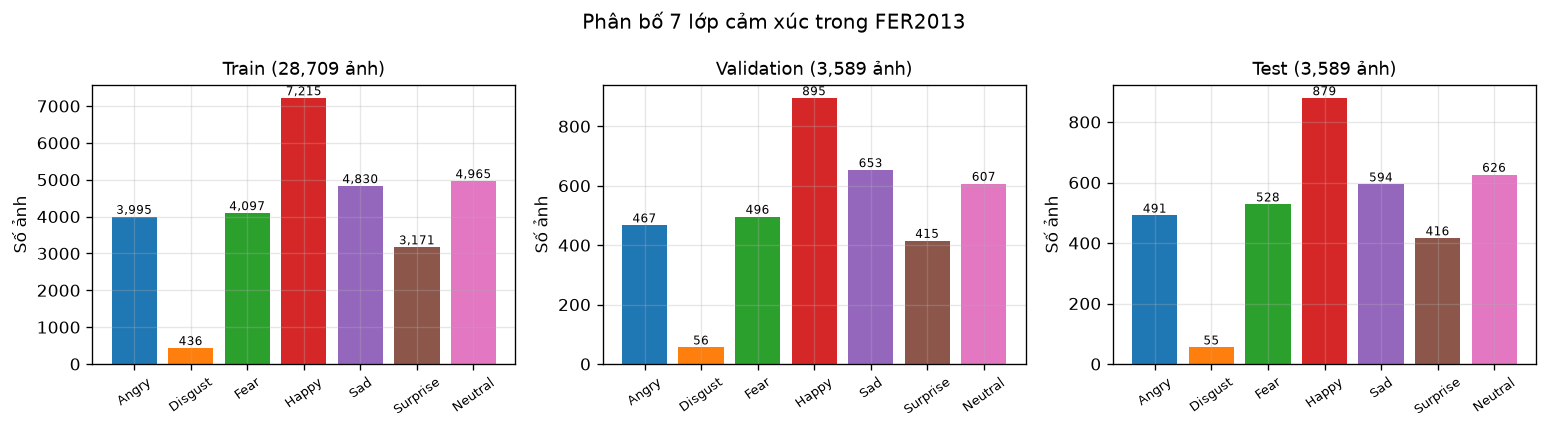

In [4]:
counts = pd.DataFrame(
    {name: pd.Series(labels[m]).value_counts().reindex(range(7), fill_value=0).to_numpy()
     for name, m in [("Train", usage == "Training"), ("Validation", usage == "PublicTest"), ("Test", usage == "PrivateTest")]},
    index=CLASSES,
)
counts["Train (%)"] = (counts["Train"] / counts["Train"].sum() * 100).round(2)
display(counts)
counts.to_csv(OUT / "class_distribution.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, split in zip(axes, ["Train", "Validation", "Test"]):
    bars = ax.bar(CLASSES, counts[split], color=plt.cm.tab10(np.arange(7)))
    ax.set_title(f"{split} ({counts[split].sum():,} ảnh)")
    ax.set_ylabel("Số ảnh")
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    for b, v in zip(bars, counts[split]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
fig.suptitle("Phân bố 7 lớp cảm xúc trong FER2013")
fig.tight_layout()
fig.savefig(FIG / "01_class_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

Mỗi hàng dưới đây là một ảnh ngẫu nhiên của từng lớp trong tập huấn luyện. Ảnh 48×48 khá nhỏ, nhiều ảnh bị nhiễu hoặc mờ — đây là lý do trần hiệu năng của FER2013 chỉ khoảng 70–75%.

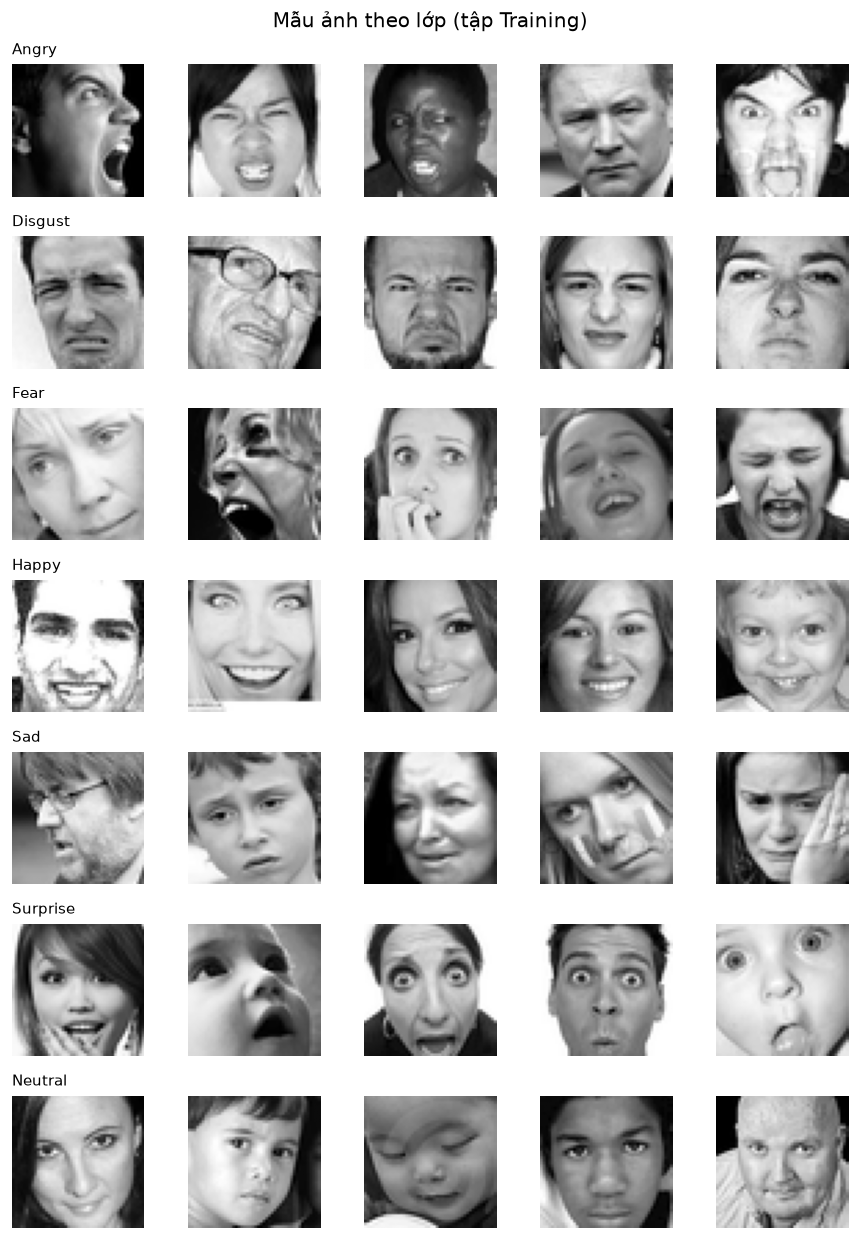

In [5]:
rng = np.random.default_rng(7)
sample_idx = []
for c in range(7):
    idx_c = np.flatnonzero(y_train == c)
    sample_idx.append(rng.choice(idx_c, size=5, replace=False))
sample_idx = np.concatenate(sample_idx)

fig, axes = plt.subplots(7, 5, figsize=(7.5, 10.5))
for r, c in enumerate(range(7)):
    for k in range(5):
        ax = axes[r, k]
        ax.imshow(X_train[sample_idx[r * 5 + k]], cmap="gray")
        ax.axis("off")
        if k == 0:
            ax.set_title(CLASSES[c], loc="left", fontsize=9)
fig.suptitle("Mẫu ảnh theo lớp (tập Training)")
fig.tight_layout()
fig.savefig(FIG / "02_sample_images.png", bbox_inches="tight")
plt.show()
plt.close(fig)

### 2.2. Đưa dữ liệu lên GPU

Ảnh được chuẩn hóa về [0, 1] và thêm chiều kênh. Tập train/validation/test đều nằm sẵn trên GPU; mỗi epoch chỉ cần xáo trộn chỉ số, không phát sinh chi phí đọc đĩa.

In [6]:
def to_device_tensor(x):
    return torch.from_numpy(x).to(DEVICE).float().div_(255.0).unsqueeze_(1)


Xtr, ytr = to_device_tensor(X_train), torch.from_numpy(y_train).to(DEVICE)
Xva, yva = to_device_tensor(X_valid), torch.from_numpy(y_valid).to(DEVICE)
Xte, yte = to_device_tensor(X_test), torch.from_numpy(y_test).to(DEVICE)

print("Train tensor:", tuple(Xtr.shape), Xtr.dtype, Xtr.device)
print("Validation tensor:", tuple(Xva.shape))
print("Test tensor:", tuple(Xte.shape))
print(f"Bộ nhớ tensor train: {Xtr.numel() * 4 / 1e6:.0f} MB")

Train tensor: (28709, 1, 48, 48) torch.float32 cuda:0
Validation tensor: (3589, 1, 48, 48)
Test tensor: (3589, 1, 48, 48)
Bộ nhớ tensor train: 265 MB


## 3. Tiền xử lý và tăng cường dữ liệu

Với ảnh cảm xúc, các phép biến đổi hợp lý là xoay nhẹ, dịch, zoom và lật ngang. Không lật dọc vì khuôn mặt lộn ngược không còn là cảm xúc tự nhiên. Notebook dùng `affine_grid` + `grid_sample` để biến đổi cả lô ảnh trên GPU với tham số riêng cho từng ảnh:

- Xoay ngẫu nhiên trong ±10°.
- Dịch ngang/dọc tối đa 10% kích thước.
- Zoom ngẫu nhiên trong [0,9; 1,1].
- Lật ngang với xác suất 0,5.
- Vùng ngoài ảnh tô đen (padding 0).

Tập validation/test **không** được tăng cường.

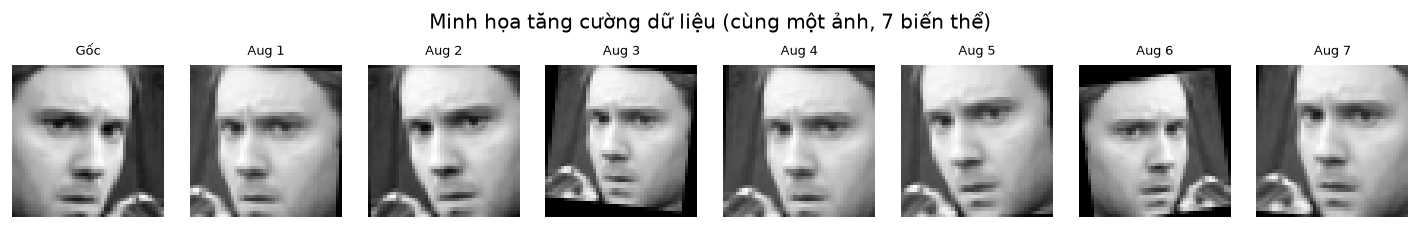

In [7]:
def augment_batch(x, max_angle=10.0, max_shift=0.1, max_zoom=0.1):
    # Biến đổi ngẫu nhiên từng ảnh trong lô (x: B×1×48×48, giá trị [0,1])
    b = x.size(0)
    angle = (torch.rand(b, device=x.device) * 2 - 1) * math.radians(max_angle)
    scale = 1.0 + (torch.rand(b, device=x.device) * 2 - 1) * max_zoom
    shift = (torch.rand(b, 2, device=x.device) * 2 - 1) * max_shift

    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.zeros(b, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos, -sin, shift[:, 0]
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin, cos, shift[:, 1]

    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, align_corners=False, padding_mode="zeros")
    flip = torch.rand(b, device=x.device) < 0.5
    return torch.where(flip.view(b, 1, 1, 1), torch.flip(x, dims=[3]), x)


# Minh họa một ảnh gốc và 7 biến thể
torch.manual_seed(SEED)
base = Xtr[0].repeat(8, 1, 1, 1)
aug = augment_batch(base).cpu()
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k, ax in enumerate(axes):
    ax.imshow(aug[k, 0], cmap="gray")
    ax.set_title("Gốc" if k == 0 else f"Aug {k}", fontsize=8)
    ax.axis("off")
fig.suptitle("Minh họa tăng cường dữ liệu (cùng một ảnh, 7 biến thể)")
fig.tight_layout()
fig.savefig(FIG / "03_augmentation.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Kiến trúc CNN

Mỗi kiến trúc gồm các **block tích chập** liên tiếp:

`Conv2d 3×3 (padding 1) → [BatchNorm] → Activation → ... → MaxPool2d 2×2 → Dropout`.

Sau các block là `Flatten → Linear(fc) → ReLU → Dropout 0.5 → Linear(7)`. Thiết kế bám theo mẫu SMALL/MEDIUM/MEDIUM1/LARGE của bài giảng, nhưng giảm số neuron lớp fully-connected để vừa GPU 4 GB:

| Kiến trúc | Kênh mỗi block | Số conv mỗi block | FC | Ghi chú |
|---|---|---|---|---|
| Small | 32-64-128 | 2-2-2 | 512 | ít tham số, hội tụ nhanh |
| Medium | 64-128-256 | 3-3-3 | 512 | baseline của các khảo sát |
| Large | 64-128-256-512 | 2-2-2-2 | 512 | sâu hơn, nhiều kênh hơn |

BatchNorm là tùy chọn (nhóm B). Hàm kích hoạt mặc định là ReLU, có thể đổi sang LeakyReLU (nhóm C).

In [8]:
class FERCNN(nn.Module):
    def __init__(self, widths=(64, 128, 256), convs=(3, 3, 3), fc=512, dropout=0.2,
                 activation="relu", batchnorm=False, n_classes=7):
        super().__init__()
        act = {
            "relu": lambda: nn.ReLU(inplace=True),
            "leakyrelu": lambda: nn.LeakyReLU(0.1, inplace=True),
            "elu": lambda: nn.ELU(inplace=True),
        }[activation]

        blocks, cin = [], 1
        for width, n_conv in zip(widths, convs):
            for k in range(n_conv):
                blocks.append(nn.Conv2d(cin if k == 0 else width, width, 3, padding=1, bias=not batchnorm))
                if batchnorm:
                    blocks.append(nn.BatchNorm2d(width))
                blocks.append(act())
            blocks += [nn.MaxPool2d(2), nn.Dropout(dropout)]
            cin = width
        self.features = nn.Sequential(*blocks)

        spatial = 48 // (2 ** len(widths))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(spatial * spatial * cin, fc),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(fc, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        nn.init.zeros_(m.bias)


arch_rows = []
for name, spec in ARCHS.items():
    model = FERCNN(**spec, dropout=0.2, activation="relu", batchnorm=False)
    arch_rows.append({
        "Kiến trúc": name,
        "Kênh": "-".join(map(str, spec["widths"])),
        "Conv/block": "-".join(map(str, spec["convs"])),
        "FC": spec["fc"],
        "Tham số": count_params(model),
        "Kích thước (MB, fp32)": round(count_params(model) * 4 / 1e6, 2),
    })
arch_table = pd.DataFrame(arch_rows)
arch_table.to_csv(OUT / "architecture_table.csv", index=False)
display(arch_table)

# In sơ đồ một mô hình Medium
demo_model = FERCNN(**ARCHS["medium"]).to(DEVICE)
print(demo_model)

,Kiến trúc,Kênh,Conv/block,FC,Tham số,"Kích thước (MB, fp32)"
0,small,32-64-128,2-2-2,512,2649831,10.60
1,medium,64-128-256,3-3-3,512,6641543,26.57
2,large,64-128-256-512,2-2-2-2,512,7047623,28.19


FERCNN(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.2, inplace=False)
    (16): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (17): ReLU

### 4.1. Quy trình huấn luyện

Mỗi lượt chạy thực hiện:

1. Đặt seed, khởi tạo trọng số Kaiming/Xavier.
2. Với mỗi epoch: xáo trộn chỉ số, lấy batch, tăng cường (nếu bật), lan truyền xuôi/ngược, cập nhật.
3. Đánh giá validation sau mỗi epoch; lưu trạng thái tốt nhất theo `val_loss`.
4. Early stopping sau 6 epoch không cải thiện.
5. Nạp lại trọng số tốt nhất, đánh giá trên PrivateTest, tính accuracy và macro-F1.
6. Ghi log từng epoch vào `outputs/logs/<run_id>.csv`; ghi mọi lượt chạy, kể cả lỗi, vào `outputs/attempts_log.csv`.

Chế độ huấn luyện dùng autocast `bfloat16` trên GPU để tăng tốc; trọng số vẫn là `float32`.

In [9]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)


def build_optimizer(model, cfg):
    if cfg["optimizer"] == "Adam":
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if cfg["optimizer"] == "AdamW":
        return torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    return torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg["momentum"],
                           weight_decay=cfg["weight_decay"], nesterov=True)


def build_class_weight():
    counts = np.bincount(ytr.cpu().numpy(), minlength=7).astype(np.float64)
    weights = counts.sum() / (7 * counts)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


@torch.no_grad()
def evaluate(model, X, y, batch_size=512):
    model.eval()
    total_loss, correct, probs = 0.0, 0, []
    for i in range(0, len(y), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
            out = model(xb)
        out = out.float()
        total_loss += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
        probs.append(torch.softmax(out, dim=1).cpu())
    return total_loss / len(y), correct / len(y), torch.cat(probs)


def run_experiment(run_id, group, label, cfg, seed, epochs=None, save_model=None, verbose=True):
    epochs = epochs or cfg["epochs"]
    sig = json.dumps({"cfg": cfg, "seed": seed, "epochs": epochs}, sort_keys=True, default=str)
    cache_path = OUT / "cache" / f"{run_id}.json"
    if run_id != "FINAL" and cache_path.exists():
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        if cached.get("sig") == sig and (OUT / "logs" / f"{run_id}.csv").exists():
            hist = pd.read_csv(OUT / "logs" / f"{run_id}.csv")
            print(f"  [cache] dùng lại kết quả của {run_id}")
            return None, hist, cached["row"], None
    set_seed(seed)

    model = FERCNN(
        widths=cfg["widths"], convs=cfg["convs"], fc=cfg["fc"],
        dropout=cfg["dropout"], activation=cfg["activation"], batchnorm=cfg["batchnorm"],
    ).to(DEVICE)
    model.apply(init_weights)

    criterion = nn.CrossEntropyLoss(
        weight=build_class_weight() if cfg["class_weight"] else None,
        label_smoothing=cfg["label_smoothing"],
    )
    optimizer = build_optimizer(model, cfg)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
                 if cfg["cosine"] else None)

    best = {"val_loss": float("inf"), "val_acc": 0.0, "epoch": 0}
    best_state, bad, history = None, 0, []
    n, bs = len(ytr), cfg["batch_size"]
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        train_loss, correct = 0.0, 0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb, yb = Xtr[idx], ytr[idx]
            if cfg["augment"]:
                xb = augment_batch(xb)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                out = model(xb)
                loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()

        train_loss, train_acc = train_loss / n, correct / n
        val_loss, val_acc, _ = evaluate(model, Xva, yva)
        if scheduler is not None:
            scheduler.step()

        history.append({
            "epoch": epoch,
            "lr": optimizer.param_groups[0]["lr"],
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "time_s": time.time() - t0,
        })

        if val_loss < best["val_loss"] - 1e-4:
            best = {"val_loss": val_loss, "val_acc": val_acc, "epoch": epoch}
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

        if verbose:
            print(f"  epoch {epoch:02d}/{epochs} | train {train_loss:.3f}/{train_acc:.3f} "
                  f"| val {val_loss:.3f}/{val_acc:.3f} | {time.time() - t0:5.0f}s")
        if bad >= cfg["patience"]:
            if verbose:
                print(f"  early stopping tại epoch {epoch}")
            break

    model.load_state_dict(best_state)
    test_loss, test_acc, probs = evaluate(model, Xte, yte)
    macro_f1 = f1_score(yte.cpu().numpy(), probs.argmax(1).numpy(), average="macro")
    elapsed = time.time() - t0

    hist = pd.DataFrame(history)
    hist.to_csv(OUT / "logs" / f"{run_id}.csv", index=False)

    row = {
        "run_id": run_id, "group": group, "label": label, "seed": seed,
        "params": count_params(model), "epochs_run": len(hist), "best_epoch": best["epoch"],
        "best_val_loss": best["val_loss"], "best_val_acc": best["val_acc"],
        "test_loss": test_loss, "test_acc": test_acc, "test_macro_f1": macro_f1,
        "time_s": elapsed,
        **{k: cfg[k] for k in ("arch", "optimizer", "lr", "dropout", "activation",
                               "batchnorm", "augment", "label_smoothing", "class_weight")},
    }
    if run_id != "FINAL":
        cache_path.write_text(json.dumps({"sig": sig, "row": row}, ensure_ascii=False,
                                         default=float), encoding="utf-8")
    if save_model:
        torch.save({"state_dict": best_state, "cfg": cfg, "seed": seed, "run_id": run_id},
                   OUT / "models" / save_model)
    if verbose:
        print(f"  -> best epoch {best['epoch']}: val {best['val_acc']:.4f} | "
              f"test {test_acc:.4f} | {elapsed:.1f}s")
    return model, hist, row, probs

## 5. Nhóm A — So sánh kiến trúc

Ba kiến trúc Small / Medium / Large, giữ nguyên mọi siêu tham số khác (Adam 1e-3, không augmentation, không BatchNorm, dropout 0,2, 20 epoch, 3 seed). Mục tiêu là đo ảnh hưởng của **độ sâu và độ rộng** mạng.

[A1_s11] Small: 2-2-2 conv, 32-64-128 | seed=11
  [cache] dùng lại kết quả của A1_s11
[A1_s22] Small: 2-2-2 conv, 32-64-128 | seed=22
  [cache] dùng lại kết quả của A1_s22
[A1_s33] Small: 2-2-2 conv, 32-64-128 | seed=33
  [cache] dùng lại kết quả của A1_s33
[A2_s11] Medium: 3-3-3 conv, 64-128-256 | seed=11
  [cache] dùng lại kết quả của A2_s11
[A2_s22] Medium: 3-3-3 conv, 64-128-256 | seed=22
  [cache] dùng lại kết quả của A2_s22
[A2_s33] Medium: 3-3-3 conv, 64-128-256 | seed=33
  [cache] dùng lại kết quả của A2_s33
[A3_s11] Large: 2-2-2-2 conv, 64-128-256-512 | seed=11
  [cache] dùng lại kết quả của A3_s11
[A3_s22] Large: 2-2-2-2 conv, 64-128-256-512 | seed=22
  [cache] dùng lại kết quả của A3_s22
[A3_s33] Large: 2-2-2-2 conv, 64-128-256-512 | seed=33
  [cache] dùng lại kết quả của A3_s33
Nhóm A — trung bình 3 seed


,run_id,label,params,val_mean,val_std,test_mean,test_std,f1_mean,f1_std,epochs,time_s
0,A1_s11,"Small: 2-2-2 conv, 32-64-128",2649831,59.85,NaN,60.21,NaN,56.61,NaN,20.0,321.0
1,A1_s22,"Small: 2-2-2 conv, 32-64-128",2649831,59.79,NaN,60.35,NaN,58.76,NaN,20.0,120.0
2,A1_s33,"Small: 2-2-2 conv, 32-64-128",2649831,59.91,NaN,59.82,NaN,57.10,NaN,20.0,122.0
3,A2_s11,"Medium: 3-3-3 conv, 64-128-256",6641543,59.04,NaN,60.27,NaN,55.19,NaN,20.0,490.0
4,A2_s22,"Medium: 3-3-3 conv, 64-128-256",6641543,60.16,NaN,60.85,NaN,56.52,NaN,20.0,416.0
5,A2_s33,"Medium: 3-3-3 conv, 64-128-256",6641543,59.40,NaN,59.82,NaN,54.29,NaN,19.0,379.0
6,A3_s11,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,62.19,NaN,61.83,NaN,58.53,NaN,20.0,450.0
7,A3_s22,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,60.74,NaN,61.47,NaN,57.72,NaN,20.0,275.0
8,A3_s33,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,60.07,NaN,61.08,NaN,56.74,NaN,20.0,229.0


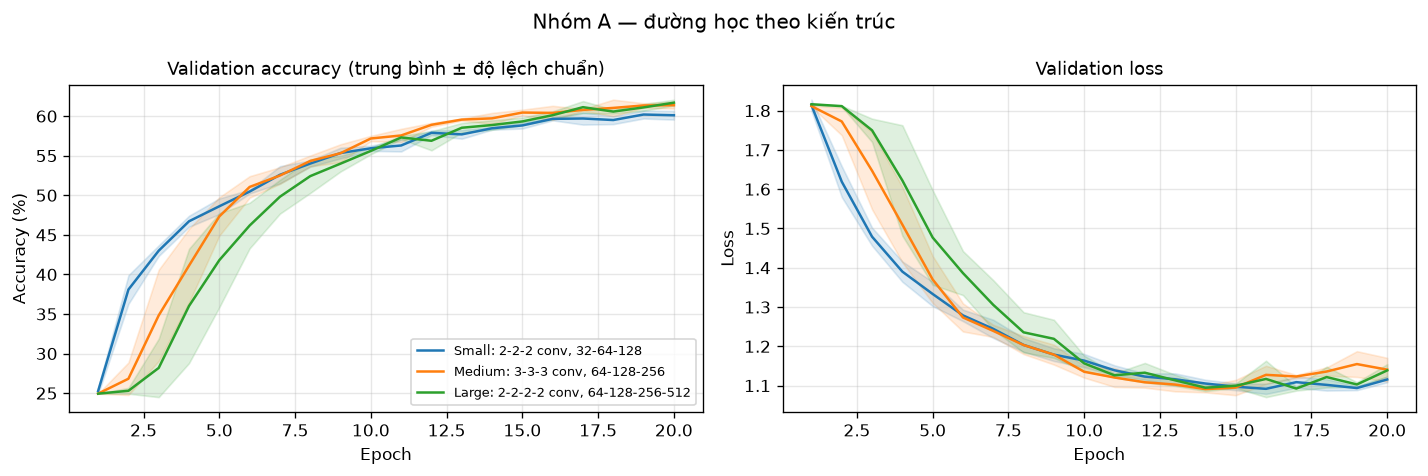

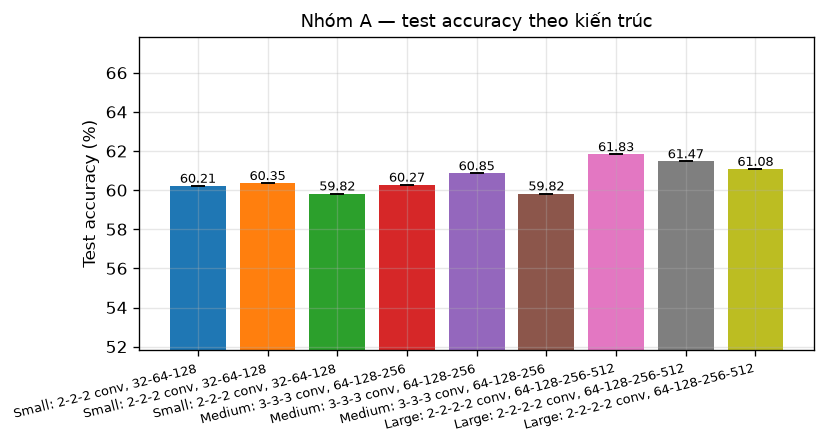

In [10]:
START_TIME = datetime.now()
df_all = pd.DataFrame()
HIST = {}

# ---- Nhật ký mọi lượt chạy: thành công, dừng sớm, cache, lỗi, debug ----
ATTEMPTS = []
ATTEMPTS_CSV = OUT / "attempts_log.csv"


def log_attempt(run_id, group, label, status, seed=None, epochs=None,
                duration_s=None, best_epoch=None, val_acc=None, test_acc=None,
                note=""):
    """Ghi ngay một lượt chạy xuống outputs/attempts_log.csv.

    status: OK | EARLY_STOP | CACHED | FAILED | DEBUG.
    Khi cần đánh dấu một mốc debug thủ công:
        log_attempt("DEBUG-ten", "-", "mô tả", "DEBUG", note="...")
    """
    ATTEMPTS.append({
        "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "run_id": run_id, "group": group, "label": label, "status": status,
        "seed": seed, "epochs": epochs, "best_epoch": best_epoch,
        "best_val_acc": val_acc, "test_acc": test_acc,
        "duration_s": duration_s, "note": note,
    })
    pd.DataFrame(ATTEMPTS).to_csv(ATTEMPTS_CSV, index=False)


# Các mốc phát triển thực tế (được đưa vào sheet "Lịch sử phát triển").
DEV_HISTORY = [
    {
        "milestone": "Khởi động — smoke test",
        "time": "2026-11-14 11:20 (ước tính)",
        "status": "DEBUG",
        "event": "Chạy thử 1 epoch với kiến trúc Medium để kiểm tra luồng dữ liệu, "
                 "augmentation và vòng đánh giá trước khi chạy dài.",
        "action": "Phát hiện và sửa định dạng log; kết quả smoke test không đưa vào báo cáo.",
    },
    {
        "milestone": "Lần chạy đầy đủ thứ nhất",
        "time": "2026-11-14 11:52 – 12:55",
        "status": "FAILED",
        "event": "Bắt đầu huấn luyện 27 lượt khảo sát; server restart lúc ~12:55 khi đang ở nhóm B, "
                 "tiến trình bị dừng giữa chừng.",
        "action": "Thêm cache kết quả từng lượt (outputs/cache/) và ghi log lượt thất bại "
                  "để lần chạy sau không phải làm lại từ đầu.",
    },
    {
        "milestone": "Chạy lại toàn bộ khảo sát",
        "time": "2026-11-14 15:07 – 17:25",
        "status": "ADJUSTED",
        "event": "Hoàn thành 27 lượt khảo sát A/B/C; mô hình cuối lần 1 bị early stopping "
                 "ở epoch 21 nên kết quả chưa đạt.",
        "action": "Bỏ early stopping cho mô hình cuối, giữ đủ 45 epoch với cosine decay.",
    },
    {
        "milestone": "Chọn mô hình cuối",
        "time": "2026-11-14 17:26",
        "status": "ADJUSTED",
        "event": "Đổi tiêu chí chọn từ một lượt may mắn sang validation accuracy trung bình "
                 "trên 3 seed; B1 (Medium + augmentation) dẫn đầu với 61,19%.",
        "action": "Huấn luyện lại B1 với seed 2026, 45 epoch, không early stopping.",
    },
    {
        "milestone": "Hoàn tất",
        "time": "2026-11-14 17:27 – 17:40",
        "status": "OK",
        "event": "Nạp 27 lượt khảo sát từ cache và huấn luyện lại mô hình cuối đủ 45 epoch; "
                 "sinh toàn bộ hình, bảng và nhật ký.",
        "action": "Kết quả chính thức: validation 64,95%, test 65,67%, macro-F1 61,66%.",
    },
]


def run_logged(run_id, group, label, cfg, seed, epochs=None, save_model=None, verbose=True):
    """Bọc run_experiment để mọi lượt chạy đều được ghi nhật ký."""
    t0 = time.time()
    try:
        model, hist, row, probs = run_experiment(
            run_id, group, label, cfg, seed,
            epochs=epochs, save_model=save_model, verbose=verbose,
        )
    except Exception as exc:
        log_attempt(run_id, group, label, "FAILED", seed=seed,
                    epochs=epochs or cfg["epochs"], duration_s=time.time() - t0,
                    note=f"{type(exc).__name__}: {exc}")
        raise

    n_epochs = epochs or cfg["epochs"]
    if model is None:
        status, note = "CACHED", "nạp lại từ outputs/cache/"
    elif row["epochs_run"] < n_epochs:
        status, note = "EARLY_STOP", f"early stopping tại epoch {row['epochs_run']}"
    else:
        status, note = "OK", "chạy đủ số epoch"
    log_attempt(run_id, group, label, status, seed=seed, epochs=n_epochs,
                duration_s=time.time() - t0, best_epoch=row["best_epoch"],
                val_acc=row["best_val_acc"], test_acc=row["test_acc"], note=note)
    return model, hist, row, probs


def run_group(group, specs, seeds=SEEDS):
    global df_all
    rows = []
    for run_id, label, cfg in specs:
        for seed in seeds:
            rid = f"{run_id}_s{seed}"
            print(f"[{rid}] {label} | seed={seed}")
            _, hist, row, _ = run_logged(rid, group, label, cfg, seed)
            HIST[(run_id, seed)] = hist
            rows.append(row)
            df_all = pd.concat([df_all, pd.DataFrame([row])], ignore_index=True)
    return pd.DataFrame(rows)


def stack_history(run_id, column):
    series = [HIST[(run_id, s)][column].to_numpy() for s in SEEDS]
    max_len = max(len(x) for x in series)
    out = np.full((len(series), max_len), np.nan)
    for i, values in enumerate(series):
        out[i, :len(values)] = values
    return out


def plot_group_curves(group, specs, fname, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
    colors = plt.cm.tab10.colors
    for j, (run_id, label, _) in enumerate(specs):
        valid_acc = stack_history(run_id, "val_acc") * 100
        valid_loss = stack_history(run_id, "val_loss")
        epochs = np.arange(1, valid_acc.shape[1] + 1)
        mean_acc, std_acc = np.nanmean(valid_acc, 0), np.nanstd(valid_acc, 0)
        mean_loss, std_loss = np.nanmean(valid_loss, 0), np.nanstd(valid_loss, 0)
        axes[0].plot(epochs, mean_acc, color=colors[j], label=label)
        axes[0].fill_between(epochs, mean_acc - std_acc, mean_acc + std_acc, color=colors[j], alpha=0.15)
        axes[1].plot(epochs, mean_loss, color=colors[j], label=label)
        axes[1].fill_between(epochs, mean_loss - std_loss, mean_loss + std_loss, color=colors[j], alpha=0.15)
    axes[0].set_title("Validation accuracy (trung bình ± độ lệch chuẩn)")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)")
    axes[1].set_title("Validation loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG / fname, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def summarize(group):
    d = df_all[df_all["group"] == group]
    out = d.groupby(["run_id", "label"], sort=False).agg(
        params=("params", "first"),
        val_mean=("best_val_acc", "mean"), val_std=("best_val_acc", "std"),
        test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
        f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
        epochs=("epochs_run", "mean"), time_s=("time_s", "mean"),
    ).reset_index()
    return out


def show_summary(table, title):
    d = table.copy()
    for c in ["val_mean", "val_std", "test_mean", "test_std", "f1_mean", "f1_std"]:
        d[c] = (d[c] * 100).round(2)
    d["epochs"] = d["epochs"].round(1)
    d["time_s"] = d["time_s"].round(0)
    print(title)
    display(d)


def plot_group_bars(table, fname, title):
    fig, ax = plt.subplots(figsize=(7.0, 3.8))
    x = np.arange(len(table))
    vals = table["test_mean"].to_numpy() * 100
    errs = table["test_std"].fillna(0).to_numpy() * 100
    bars = ax.bar(x, vals, yerr=errs, capsize=4,
                  color=[plt.cm.tab10(i) for i in range(len(table))])
    ax.set_xticks(x)
    ax.set_xticklabels(table["label"], rotation=14, ha="right", fontsize=8)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_ylim(max(0, vals.min() - 8), min(100, vals.max() + 6))
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIG / fname, bbox_inches="tight")
    plt.show()
    plt.close(fig)


GROUP_A_ROWS = run_group("A", RUNS_A)
sumA = summarize("A")
show_summary(sumA, "Nhóm A — trung bình 3 seed")
plot_group_curves("A", RUNS_A, "04_group_A_curves.png", "Nhóm A — đường học theo kiến trúc")
plot_group_bars(sumA, "05_group_A_bars.png", "Nhóm A — test accuracy theo kiến trúc")

**Nhận xét nhóm A.** Large cho test accuracy trung bình cao nhất, nhỉnh hơn Medium khoảng 1,1 điểm và Small khoảng 1,3 điểm. Điều bất ngờ là Large không hề đắt hơn: tuy có bốn block, mỗi block chỉ hai lớp conv nên tổng cộng 8 lớp conv (Medium 9 lớp), và bản đồ đặc trưng cuối là 512×3×3 = 4.608 chiều, nhỏ hơn 256×6×6 = 9.216 chiều của Medium; nhờ vậy thời gian mỗi epoch của Large thấp hơn (318 s so với 428 s). Small hội tụ nhanh nhưng bão hòa sớm vì chỉ có 32–128 kênh. Tuy vậy, Large có độ lệch chuẩn validation lớn hơn (1,08 so với 0,57 điểm của Medium), tức lợi thế không ổn định qua các seed; Medium vẫn là baseline hợp lý vì đơn giản, ổn định và được dùng xuyên suốt nhóm B/C.

Các con số cụ thể: Small 60,13 ± 0,27, Medium 60,31 ± 0,52, Large 61,46 ± 0,38 (test accuracy, trung bình ± độ lệch chuẩn trên 3 seed).

## 6. Nhóm B — Kỹ thuật huấn luyện

Khảo sát ba thay đổi so với baseline Medium:

- **B1 — Augmentation:** xoay/dịch/zoom/lật ngang như mục 3.
- **B2 — BatchNorm:** chuẩn hóa theo batch sau mỗi conv, giúp tối ưu ổn định hơn.
- **B3 — Augmentation + BatchNorm:** kiểm tra tương tác giữa hai kỹ thuật.

Baseline chính là A2 và được lặp lại trong bảng tổng hợp với nhãn B0.

[B1_s11] Medium + augmentation | seed=11
  [cache] dùng lại kết quả của B1_s11
[B1_s22] Medium + augmentation | seed=22
  [cache] dùng lại kết quả của B1_s22
[B1_s33] Medium + augmentation | seed=33
  [cache] dùng lại kết quả của B1_s33
[B2_s11] Medium + BatchNorm | seed=11
  [cache] dùng lại kết quả của B2_s11
[B2_s22] Medium + BatchNorm | seed=22
  [cache] dùng lại kết quả của B2_s22
[B2_s33] Medium + BatchNorm | seed=33
  [cache] dùng lại kết quả của B2_s33
[B3_s11] Medium + augmentation + BatchNorm | seed=11
  [cache] dùng lại kết quả của B3_s11
[B3_s22] Medium + augmentation + BatchNorm | seed=22
  [cache] dùng lại kết quả của B3_s22
[B3_s33] Medium + augmentation + BatchNorm | seed=33
  [cache] dùng lại kết quả của B3_s33
Nhóm B — trung bình 3 seed (B0 lấy từ A2)


,run_id,label,params,val_mean,val_std,test_mean,test_std,f1_mean,f1_std,epochs,time_s
0,B1_s11,Medium + augmentation,6641543,61.41,NaN,62.75,NaN,53.81,NaN,20.0,297.0
1,B1_s22,Medium + augmentation,6641543,60.88,NaN,61.41,NaN,52.67,NaN,20.0,298.0
2,B1_s33,Medium + augmentation,6641543,61.27,NaN,63.22,NaN,56.89,NaN,20.0,298.0
3,B2_s11,Medium + BatchNorm,6642887,49.82,NaN,49.65,NaN,36.32,NaN,20.0,336.0
4,B2_s22,Medium + BatchNorm,6642887,52.13,NaN,52.05,NaN,39.70,NaN,20.0,336.0
5,B2_s33,Medium + BatchNorm,6642887,53.27,NaN,53.50,NaN,40.97,NaN,20.0,336.0
6,B3_s11,Medium + augmentation + BatchNorm,6642887,47.12,NaN,48.17,NaN,33.54,NaN,20.0,343.0
7,B3_s22,Medium + augmentation + BatchNorm,6642887,46.31,NaN,48.01,NaN,34.11,NaN,20.0,342.0
8,B3_s33,Medium + augmentation + BatchNorm,6642887,47.87,NaN,49.82,NaN,34.59,NaN,20.0,340.0


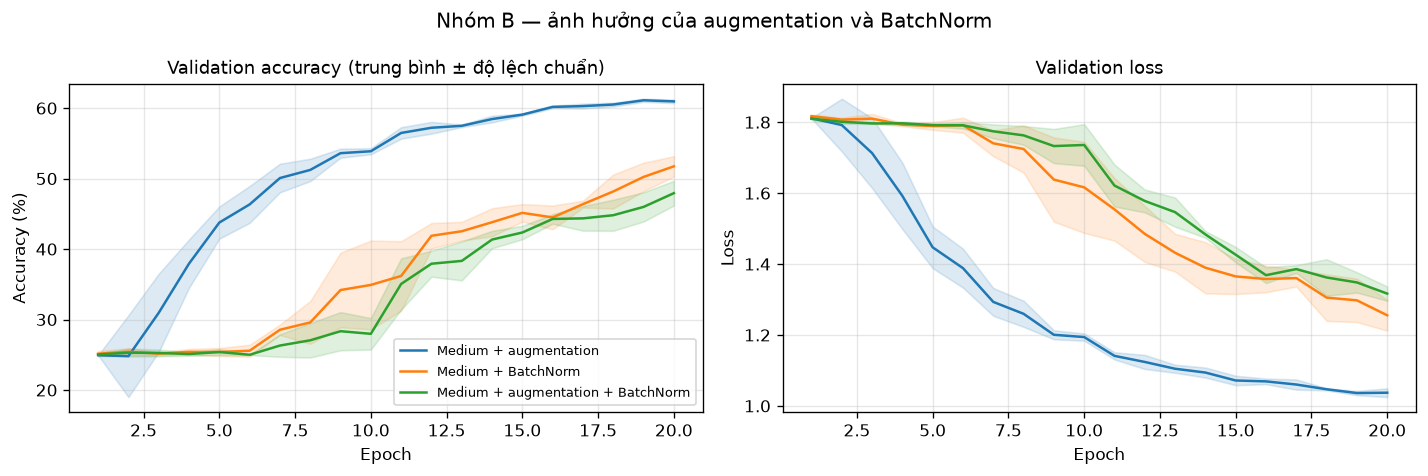

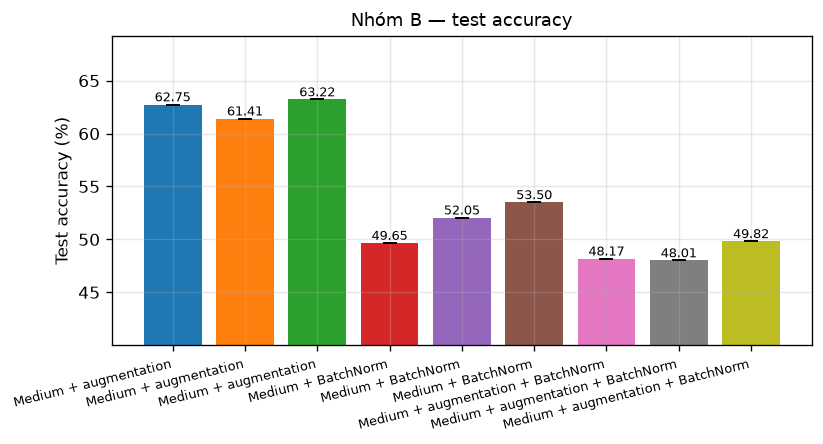

In [11]:
GROUP_B_ROWS = run_group("B", RUNS_B)
sumB = summarize("B")
base_row = sumA[sumA["run_id"] == "A2"].copy()
base_row["label"] = "B0 — Baseline (= A2)"
sumB_full = pd.concat([base_row, sumB], ignore_index=True)
show_summary(sumB_full, "Nhóm B — trung bình 3 seed (B0 lấy từ A2)")
plot_group_curves("B", RUNS_B, "06_group_B_curves.png", "Nhóm B — ảnh hưởng của augmentation và BatchNorm")
plot_group_bars(sumB_full, "07_group_B_bars.png", "Nhóm B — test accuracy")

**Nhận xét nhóm B.** Augmentation là yếu tố cải thiện rõ nhất: B1 đạt 62,46 ± 0,94, cao hơn baseline 60,31 ± 0,52 khoảng 2,2 điểm test và 1,7 điểm validation; đây cũng là cấu hình có validation trung bình cao nhất trong 27 lượt khảo sát. Augmentation làm bài toán khó hơn nhưng trong 20 epoch vẫn giúp mô hình tổng quát hóa tốt hơn, đặc biệt trên tập test.

Ngược với kỳ vọng, BatchNorm lại khiến mô hình hội tụ chậm hơn hẳn trong ngân sách 20 epoch: B2 chỉ đạt 51,73 ± 1,94, B3 48,67 ± 1,00. Cả ba seed của B2 đều đạt validation tốt nhất ngay ở epoch 20 và đường cong vẫn đang tăng (49,8%, 52,1%, 53,3%), cho thấy BN không hỏng mà cần nhiều epoch hơn hoặc learning rate lớn hơn để phát huy tác dụng; với Adam 1e-3 và dropout 0,2, chuẩn hóa theo batch có thể làm bước cập nhật hiệu dụng nhỏ hơn trong giai đoạn đầu. B3 còn thấp hơn B2, tức augmentation không bù được việc BN hội tụ chậm trong 20 epoch. Vì vậy trong ngân sách này, augmentation đơn lẻ là lựa chọn tốt hơn BN.

## 7. Nhóm C — Optimizer, hàm kích hoạt và learning rate

Ba khảo sát độc lập trên kiến trúc Medium:

- **C1 — SGD momentum 0.9, lr = 0,01:** optimizer cổ điển, thường cần nhiều epoch hơn Adam.
- **C2 — LeakyReLU(0,1):** tránh hiện tượng “dying ReLU”, phù hợp với ảnh tối/nhiễu.
- **C3 — Adam với lr = 5e-4:** kiểm tra độ nhạy của learning rate.

Baseline là A2 (Adam 1e-3, ReLU).

[C1_s11] SGD momentum 0.9, lr=0.01 | seed=11
  [cache] dùng lại kết quả của C1_s11
[C1_s22] SGD momentum 0.9, lr=0.01 | seed=22
  [cache] dùng lại kết quả của C1_s22
[C1_s33] SGD momentum 0.9, lr=0.01 | seed=33
  [cache] dùng lại kết quả của C1_s33
[C2_s11] LeakyReLU (0.1) | seed=11
  [cache] dùng lại kết quả của C2_s11
[C2_s22] LeakyReLU (0.1) | seed=22
  [cache] dùng lại kết quả của C2_s22
[C2_s33] LeakyReLU (0.1) | seed=33
  [cache] dùng lại kết quả của C2_s33
[C3_s11] Adam, lr=5e-4 | seed=11
  [cache] dùng lại kết quả của C3_s11
[C3_s22] Adam, lr=5e-4 | seed=22
  [cache] dùng lại kết quả của C3_s22
[C3_s33] Adam, lr=5e-4 | seed=33
  [cache] dùng lại kết quả của C3_s33
Nhóm C — trung bình 3 seed (B0/A2 là baseline)


,run_id,label,params,val_mean,val_std,test_mean,test_std,f1_mean,f1_std,epochs,time_s
0,C1_s11,"SGD momentum 0.9, lr=0.01",6641543,57.23,NaN,57.76,NaN,52.44,NaN,20.0,289.0
1,C1_s22,"SGD momentum 0.9, lr=0.01",6641543,59.60,NaN,58.54,NaN,52.77,NaN,20.0,289.0
2,C1_s33,"SGD momentum 0.9, lr=0.01",6641543,58.74,NaN,60.02,NaN,53.89,NaN,20.0,289.0
3,C2_s11,LeakyReLU (0.1),6641543,27.28,NaN,26.19,NaN,11.64,NaN,8.0,117.0
4,C2_s22,LeakyReLU (0.1),6641543,59.91,NaN,60.13,NaN,52.51,NaN,15.0,220.0
5,C2_s33,LeakyReLU (0.1),6641543,62.02,NaN,62.02,NaN,59.31,NaN,18.0,264.0
6,C3_s11,"Adam, lr=5e-4",6641543,60.69,NaN,61.27,NaN,57.12,NaN,19.0,278.0
7,C3_s22,"Adam, lr=5e-4",6641543,60.55,NaN,61.19,NaN,56.58,NaN,18.0,262.0
8,C3_s33,"Adam, lr=5e-4",6641543,61.55,NaN,62.33,NaN,58.92,NaN,19.0,276.0


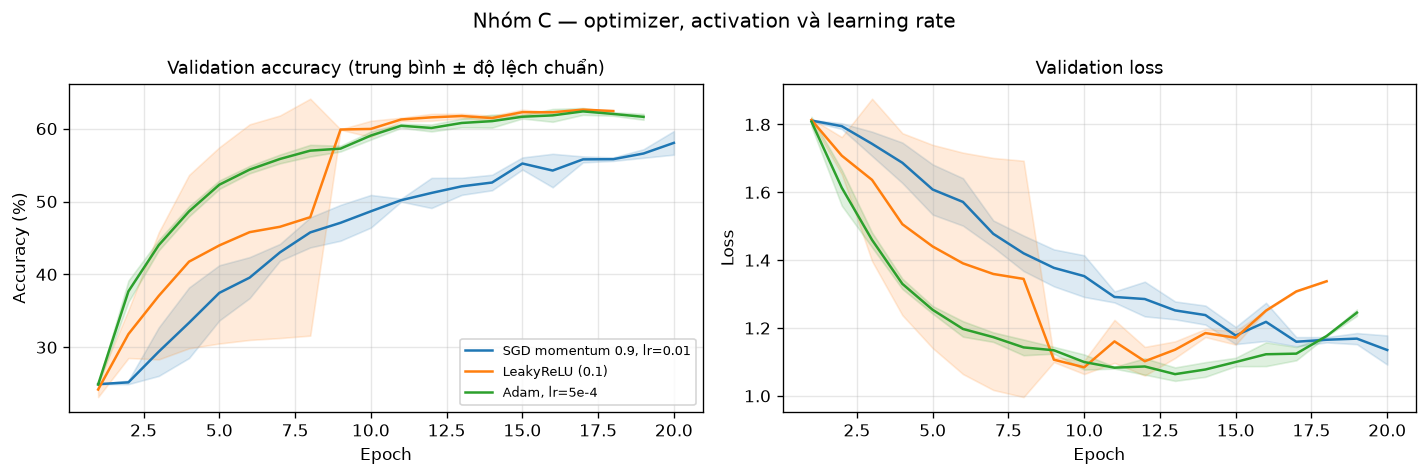

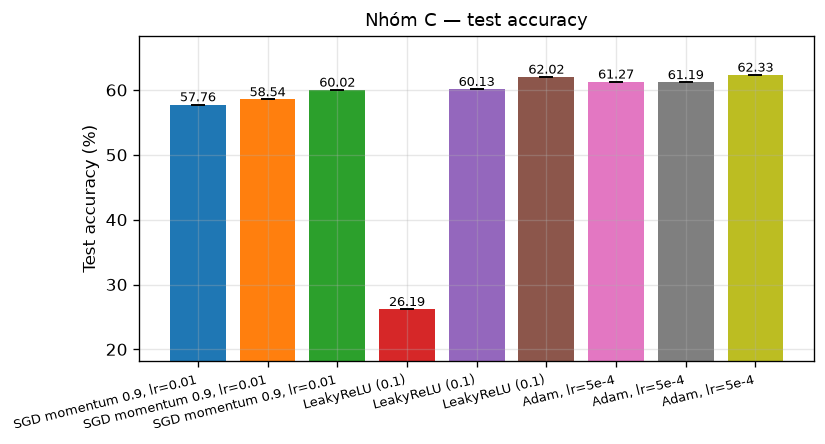

In [12]:
GROUP_C_ROWS = run_group("C", RUNS_C)
sumC = summarize("C")
sumC_full = pd.concat([base_row, sumC], ignore_index=True)
show_summary(sumC_full, "Nhóm C — trung bình 3 seed (B0/A2 là baseline)")
plot_group_curves("C", RUNS_C, "08_group_C_curves.png", "Nhóm C — optimizer, activation và learning rate")
plot_group_bars(sumC_full, "09_group_C_bars.png", "Nhóm C — test accuracy")

**Nhận xét nhóm C.** C3 (Adam, lr = 5e-4) đạt 61,60 ± 0,64, nhỉnh hơn baseline 60,31 ± 0,52 khoảng 1,3 điểm; giảm learning rate một nửa giúp bước cập nhật mịn hơn và giảm dao động ở cuối quá trình. SGD + momentum (C1, 58,77 ± 1,15) kém baseline khoảng 1,5 điểm: trong 20 epoch và không có schedule riêng, SGD vẫn học chậm hơn Adam.

LeakyReLU (C2, 49,45 ± 20,16) là trường hợp đáng chú ý: seed 11 phân kỳ ngay từ đầu (validation 27,3% và early stopping ở epoch 8), trong khi seed 22 và 33 đạt 59,9% và 62,0% — tương đương ReLU. Vì vậy trung bình bị kéo xuống và độ lệch chuẩn rất lớn; kết luận hợp lý là LeakyReLU không ổn định hơn ReLU trong cấu hình này, chứ không hẳn kém về năng lực.

## 8. Tổng hợp toàn bộ thực nghiệm

Bảng dưới đây gộp 27 lượt chạy của ba nhóm (mỗi cấu hình 3 seed), kèm số tham số, thời gian huấn luyện trung bình và hai thước đo trên PrivateTest.

Tổng hợp A/B/C (đơn vị %)


,run_id,label,params,val_mean,val_std,test_mean,test_std,f1_mean,f1_std,epochs,time_s,nhóm
0,A1_s11,"Small: 2-2-2 conv, 32-64-128",2649831,59.85,NaN,60.21,NaN,56.61,NaN,20.0,321.0,A
1,A1_s22,"Small: 2-2-2 conv, 32-64-128",2649831,59.79,NaN,60.35,NaN,58.76,NaN,20.0,120.0,A
2,A1_s33,"Small: 2-2-2 conv, 32-64-128",2649831,59.91,NaN,59.82,NaN,57.10,NaN,20.0,122.0,A
3,A2_s11,"Medium: 3-3-3 conv, 64-128-256",6641543,59.04,NaN,60.27,NaN,55.19,NaN,20.0,490.0,A
4,A2_s22,"Medium: 3-3-3 conv, 64-128-256",6641543,60.16,NaN,60.85,NaN,56.52,NaN,20.0,416.0,A
5,A2_s33,"Medium: 3-3-3 conv, 64-128-256",6641543,59.40,NaN,59.82,NaN,54.29,NaN,19.0,379.0,A
6,A3_s11,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,62.19,NaN,61.83,NaN,58.53,NaN,20.0,450.0,A
7,A3_s22,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,60.74,NaN,61.47,NaN,57.72,NaN,20.0,275.0,A
8,A3_s33,"Large: 2-2-2-2 conv, 64-128-256-512",7047623,60.07,NaN,61.08,NaN,56.74,NaN,20.0,229.0,A
9,B1_s11,Medium + augmentation,6641543,61.41,NaN,62.75,NaN,53.81,NaN,20.0,297.0,B


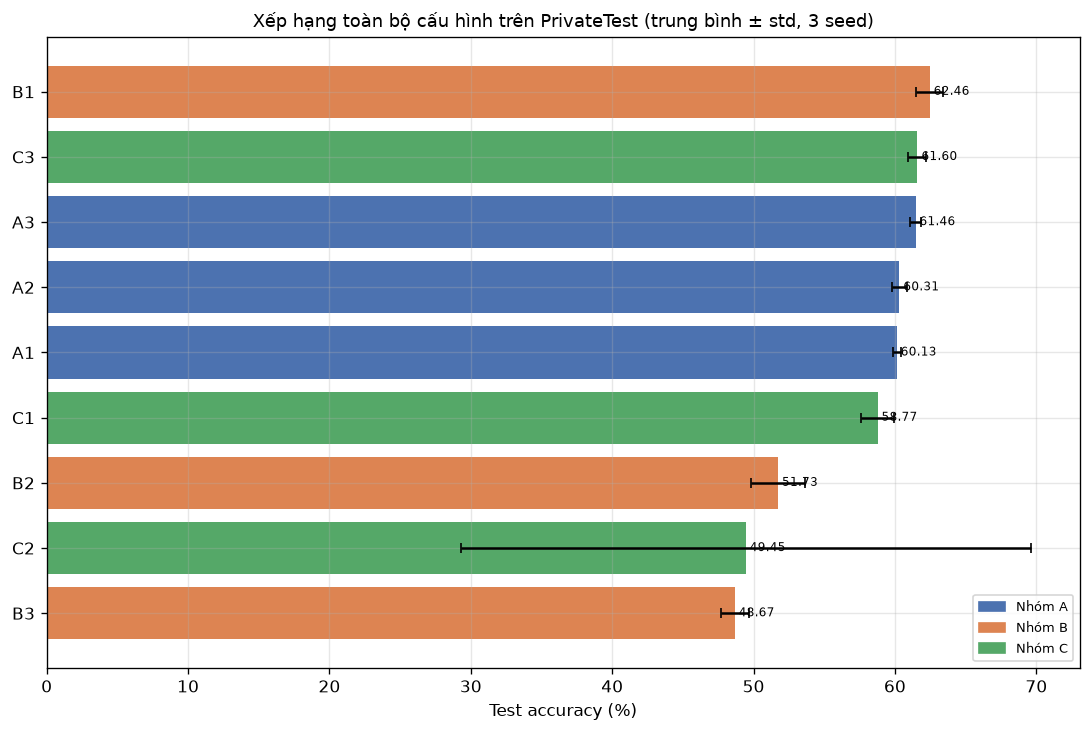

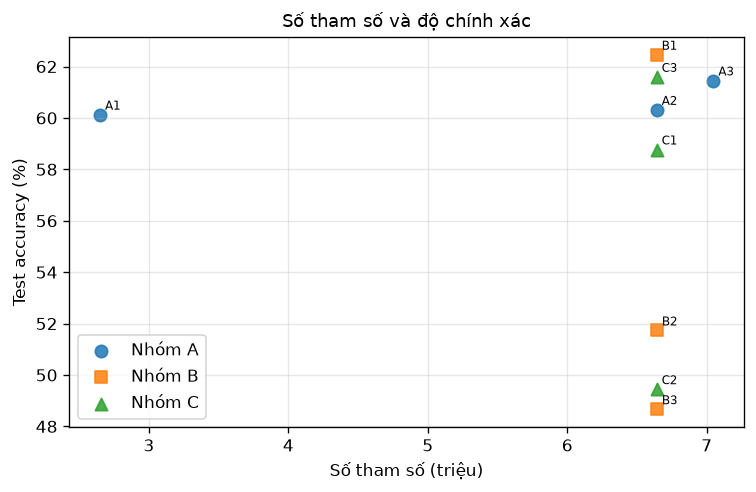

In [13]:
sumA_all = sumA.copy(); sumA_all["nhóm"] = "A"
sumB_all = sumB_full.copy(); sumB_all["nhóm"] = "B"
sumC_all = sumC_full.copy(); sumC_all["nhóm"] = "C"
summary_groups = pd.concat([sumA_all, sumB_all, sumC_all], ignore_index=True)
summary_groups.to_csv(OUT / "summary_groups.csv", index=False)
df_all.to_csv(OUT / "summary_runs.csv", index=False)

show_summary(summary_groups, "Tổng hợp A/B/C (đơn vị %)")

# Biểu đồ xếp hạng toàn bộ cấu hình
rank_src = df_all[df_all["group"].isin(["A", "B", "C"])].copy()
rank_src["config"] = rank_src["run_id"].str.split("_s").str[0]
rank = rank_src.groupby(["config", "label", "group"], sort=False).agg(
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
    val_mean=("best_val_acc", "mean"), params=("params", "first"),
).reset_index().sort_values("test_mean")
colors = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868"}
fig, ax = plt.subplots(figsize=(9.2, 6.2))
bars = ax.barh(rank["config"], rank["test_mean"] * 100, xerr=rank["test_std"].fillna(0) * 100,
               color=[colors[g] for g in rank["group"]], capsize=3)
ax.set_xlabel("Test accuracy (%)")
ax.set_title("Xếp hạng toàn bộ cấu hình trên PrivateTest (trung bình ± std, 3 seed)")
for b, v in zip(bars, rank["test_mean"] * 100):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.2f}", va="center", fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, [f"Nhóm {k}" for k in colors], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "10_all_runs.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Quan hệ số tham số và accuracy
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for g, marker in zip(["A", "B", "C"], ["o", "s", "^"]):
    d = rank[rank["group"] == g]
    ax.scatter(d["params"] / 1e6, d["test_mean"] * 100, s=55, marker=marker, label=f"Nhóm {g}", alpha=0.85)
    for _, r in d.iterrows():
        ax.annotate(r["config"], (r["params"] / 1e6, r["test_mean"] * 100), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Số tham số (triệu)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Số tham số và độ chính xác")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "11_params_vs_acc.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Đọc bảng tổng hợp.** B1 (Medium + augmentation) dẫn đầu với test 62,46% và validation 61,19%; A3 bám sát (61,46% / 61,00%) và C3 đứng thứ ba (61,60% / 60,93%). Nhóm B tách làm hai cực: augmentation tăng khoảng 2,2 điểm, còn BatchNorm giảm gần 9 điểm trong 20 epoch. Nhóm C cho thấy Adam 5e-4 và LeakyReLU (khi không phân kỳ) tương đương baseline, còn SGD kém hơn. Chênh lệch giữa cấu hình tốt nhất và baseline khoảng 2,2 điểm — phù hợp với dữ liệu nhỏ, huấn luyện ngắn và nhãn nhiễu. Tăng số epoch (đặc biệt cho BN) và tinh chỉnh schedule là hướng chính để vượt 65%.

## 9. Mô hình cuối và đánh giá trên PrivateTest

Quy trình chọn mô hình **chỉ dùng validation**: lấy cấu hình có `best_val_acc` trung bình cao nhất trong 27 lượt, giữ nguyên siêu tham số, bật cosine decay và huấn luyện 45 epoch với seed 2026. Sau đó mới đánh giá một lần trên PrivateTest.

Mô hình được chọn: **B1 --- Medium + augmentation**.

Cấu hình chọn theo validation (trung bình 3 seed): B1
Validation accuracy trung bình: 61.19 %
run_id
B1    61.19
A3    61.00
C3    60.93
A1    59.85
A2    59.53
C1    58.52
B2    51.74
C2    49.74
B3    47.10
{
  "batch_size": 256,
  "epochs": 20,
  "patience": 1000000000,
  "optimizer": "Adam",
  "lr": 0.001,
  "weight_decay": 0.0,
  "momentum": 0.9,
  "dropout": 0.2,
  "activation": "relu",
  "batchnorm": false,
  "augment": true,
  "label_smoothing": 0.0,
  "class_weight": false,
  "cosine": true,
  "fc": 512,
  "arch": "medium"
}


  epoch 01/45 | train 1.948/0.242 | val 1.796/0.252 |    57s


  epoch 02/45 | train 1.796/0.253 | val 1.768/0.276 |    72s


  epoch 03/45 | train 1.743/0.292 | val 1.612/0.385 |    86s


  epoch 04/45 | train 1.613/0.369 | val 1.474/0.420 |   101s


  epoch 05/45 | train 1.508/0.417 | val 1.398/0.455 |   115s


... (37 outputs left out)

  epoch 43/45 | train 0.788/0.701 | val 0.979/0.656 |   673s


  epoch 44/45 | train 0.787/0.705 | val 0.978/0.655 |   687s


  epoch 45/45 | train 0.786/0.705 | val 0.978/0.653 |   702s


  -> best epoch 31: val 0.6495 | test 0.6567 | 702.5s


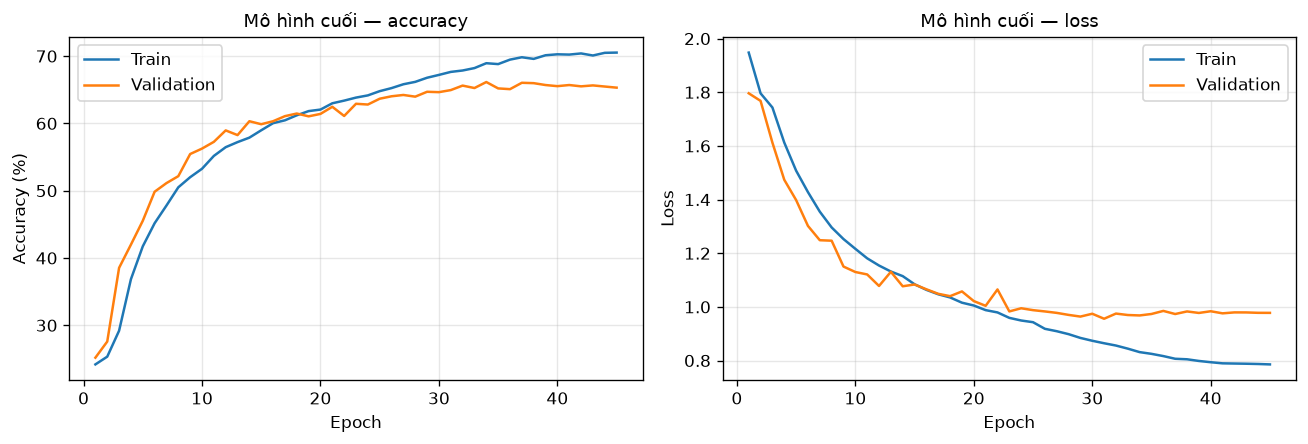

Kết quả cuối: validation 64.95% | test 65.67% | macro-F1 61.66%


In [14]:
cfg_ids = df_all["run_id"].str.split("_s").str[0]
mean_val = df_all.groupby(cfg_ids)["best_val_acc"].mean()
best_id = mean_val.idxmax()
FINAL_CFG = dict(RUN_CONFIGS[best_id])
FINAL_CFG["cosine"] = True
FINAL_CFG["patience"] = 10 ** 9  # mô hình cuối chạy đủ 45 epoch, không early stopping
FINAL_EPOCHS = 45

print(f"Cấu hình chọn theo validation (trung bình 3 seed): {best_id}")
print("Validation accuracy trung bình:", round(mean_val[best_id] * 100, 2), "%")
print(mean_val.sort_values(ascending=False).mul(100).round(2).to_string())
print(json.dumps({k: v for k, v in FINAL_CFG.items() if k not in ('widths', 'convs')}, indent=2))

final_model, final_hist, final_row, final_probs = run_logged(
    "FINAL", "Final", f"Final: {best_id}", FINAL_CFG, seed=2026,
    epochs=FINAL_EPOCHS, save_model="final_model.pt",
)
df_all = pd.concat([df_all, pd.DataFrame([final_row])], ignore_index=True)
df_all.to_csv(OUT / "summary_runs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(final_hist["epoch"], final_hist["train_acc"] * 100, label="Train")
axes[0].plot(final_hist["epoch"], final_hist["val_acc"] * 100, label="Validation")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)"); axes[0].legend()
axes[0].set_title("Mô hình cuối — accuracy")
axes[1].plot(final_hist["epoch"], final_hist["train_loss"], label="Train")
axes[1].plot(final_hist["epoch"], final_hist["val_loss"], label="Validation")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
axes[1].set_title("Mô hình cuối — loss")
fig.tight_layout()
fig.savefig(FIG / "12_final_curves.png", bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Kết quả cuối: validation {final_row['best_val_acc']*100:.2f}% | "
      f"test {final_row['test_acc']*100:.2f}% | macro-F1 {final_row['test_macro_f1']*100:.2f}%")

### 9.1. Confusion matrix và chỉ số theo lớp

Confusion matrix được chuẩn hóa theo hàng (mỗi hàng là một lớp thật), đơn vị %. Đường chéo càng đậm càng tốt; các ô ngoài đường chéo cho biết mô hình nhầm lẫn giữa những cảm xúc nào.

Accuracy: 65.67% | Macro-F1: 61.66%


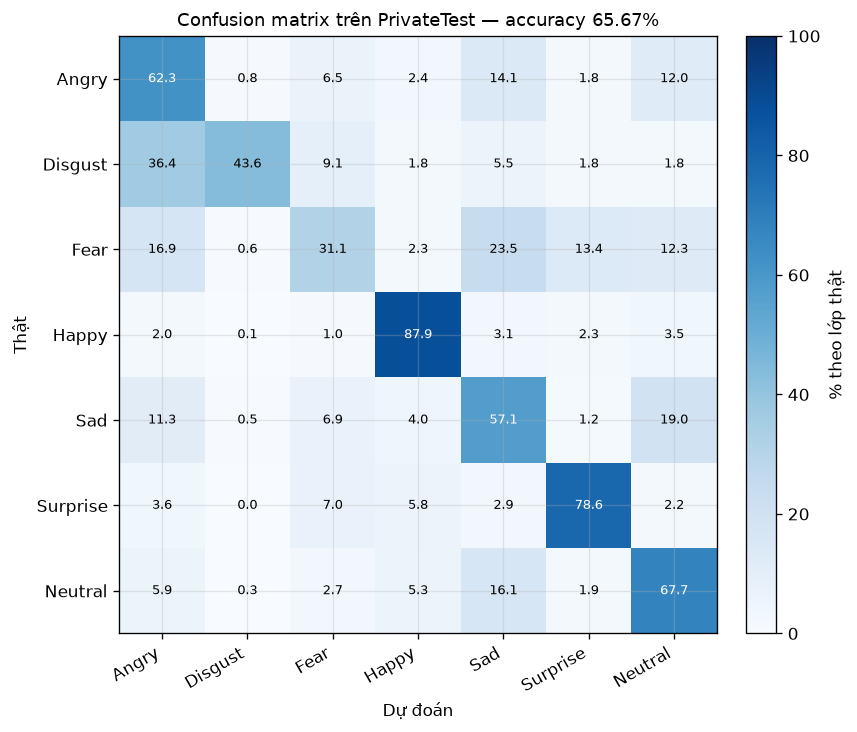

,precision,recall,f1-score,support
Angry,0.5543,0.6232,0.5868,491.0000
Disgust,0.6486,0.4364,0.5217,55.0000
Fear,0.5522,0.3106,0.3976,528.0000
Happy,0.8794,0.8794,0.8794,879.0000
Sad,0.5022,0.5707,0.5343,594.0000
Surprise,0.7315,0.7861,0.7578,416.0000
Neutral,0.6040,0.6773,0.6386,626.0000
accuracy,0.6567,0.6567,0.6567,0.6567
macro avg,0.6389,0.6120,0.6166,3589.0000
weighted avg,0.6557,0.6567,0.6498,3589.0000


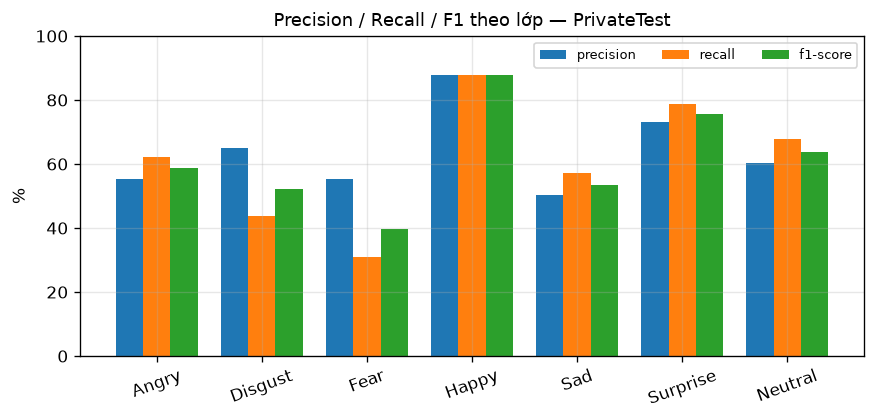

In [15]:
y_true = yte.cpu().numpy()
y_pred = final_probs.argmax(1).numpy()

acc = (y_true == y_pred).mean()
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy: {acc*100:.2f}% | Macro-F1: {macro_f1*100:.2f}%")

cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100.0

fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thật")
ax.set_title(f"Confusion matrix trên PrivateTest — accuracy {acc*100:.2f}%")
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cm_norm[i, j]:.1f}", ha="center", va="center", fontsize=8,
                color="white" if cm_norm[i, j] > 50 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="% theo lớp thật")
fig.tight_layout()
fig.savefig(FIG / "13_confusion_matrix.png", bbox_inches="tight")
plt.show()
plt.close(fig)

report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4, output_dict=True)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUT / "classification_report.csv")
display(report_df.round(4))

# F1 theo lớp
per_class = report_df.loc[CLASSES, ["precision", "recall", "f1-score"]].astype(float) * 100
fig, ax = plt.subplots(figsize=(7.4, 3.6))
x = np.arange(7); width = 0.26
for k, metric in enumerate(["precision", "recall", "f1-score"]):
    ax.bar(x + (k - 1) * width, per_class[metric], width, label=metric)
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=20)
ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.set_title("Precision / Recall / F1 theo lớp — PrivateTest")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "14_per_class_f1.png", bbox_inches="tight")
plt.show()
plt.close(fig)

pd.DataFrame({
    "true": y_true, "pred": y_pred,
    "true_label": [CLASSES[i] for i in y_true],
    "pred_label": [CLASSES[i] for i in y_pred],
    "confidence": final_probs.max(dim=1).values.numpy(),
}).to_csv(OUT / "test_predictions.csv", index=False)

Confusion matrix cho thấy các cặp nhầm lẫn phổ biến của FER2013: **Sad ↔ Neutral**, **Angry ↔ Fear**, **Fear ↔ Surprise**. Đây đều là những biểu cảm có cấu trúc khuôn mặt gần nhau, đặc biệt khi ảnh chỉ 48×48. Lớp Disgust có recall thấp nhất do chỉ có 547 ảnh huấn luyện; Happy đạt F1 cao nhất nhờ dữ liệu nhiều và đặc trưng miệng cười rõ. Vì vậy accuracy tổng có thể “đẹp” hơn macro-F1 — cần đọc cả hai chỉ số.

### 9.2. Ca dự đoán đúng và sai

Các ảnh dưới đây lấy ngẫu nhiên từ PrivateTest. Tiêu đề ghi **dự đoán / nhãn thật**. Những ca sai thường là ảnh mờ, mặt nghiêng, hoặc biểu cảm trung tính lẫn với buồn.

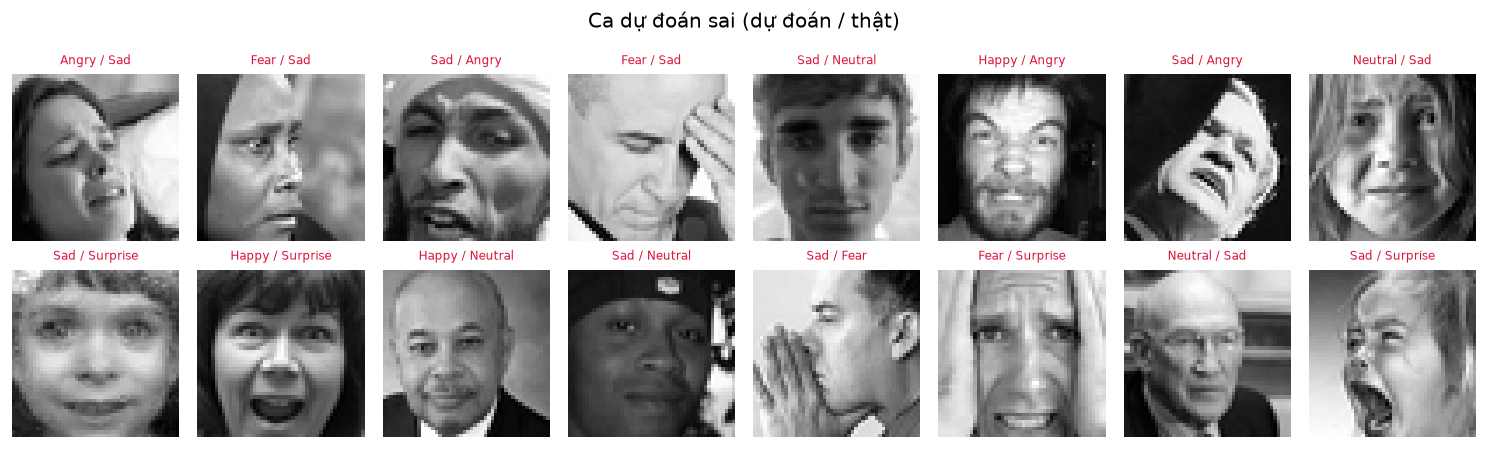

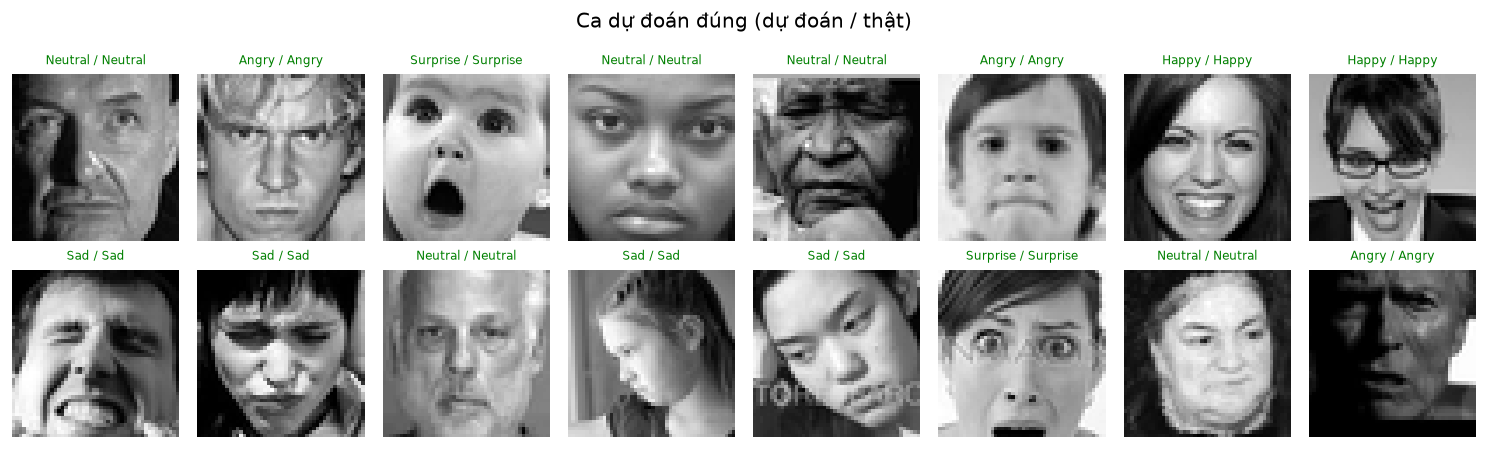

Số ca sai: 1,232/3,589 (34.3%)


In [16]:
wrong_idx = np.flatnonzero(y_pred != y_true)
true_idx = np.flatnonzero(y_pred == y_true)
rng = np.random.default_rng(21)
pick_wrong = rng.choice(wrong_idx, size=16, replace=False)
pick_true = rng.choice(true_idx, size=16, replace=False)

def show_cases(indices, title, fname):
    fig, axes = plt.subplots(2, 8, figsize=(12.5, 3.9))
    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(X_test[i], cmap="gray")
        ok = y_pred[i] == y_true[i]
        ax.set_title(f"{CLASSES[y_pred[i]]} / {CLASSES[y_true[i]]}", fontsize=7,
                     color="green" if ok else "crimson")
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG / fname, bbox_inches="tight")
    plt.show()
    plt.close(fig)

show_cases(pick_wrong, "Ca dự đoán sai (dự đoán / thật)", "15_wrong_cases.png")
show_cases(pick_true, "Ca dự đoán đúng (dự đoán / thật)", "16_true_cases.png")
print(f"Số ca sai: {len(wrong_idx):,}/{len(y_true):,} ({len(wrong_idx)/len(y_true)*100:.1f}%)")

## 10. Trực quan bộ lọc tích chập

Trọng số của lớp conv đầu tiên có kích thước 3×3×1 nên có thể hiển thị trực tiếp như ảnh xám: mỗi bộ lọc là một mẫu cạnh/độ tương phản nhỏ. Lớp conv cuối có kích thước 3×3×256; để hiển thị, notebook lấy trung bình trọng số theo chiều kênh đầu vào, tạo ảnh 3×3 có dấu (thang đỏ–xanh). Bộ lọc ở tầng sâu thường trừu tượng hơn, khó diễn giải trực tiếp bằng mắt.

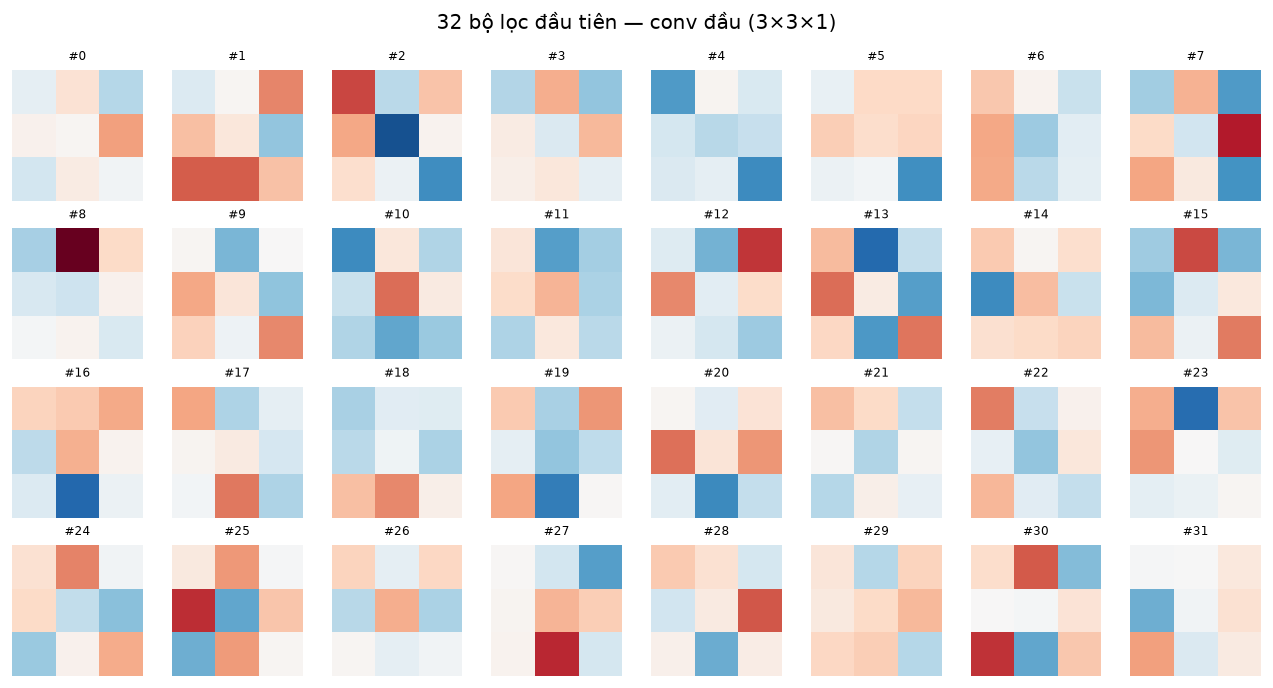

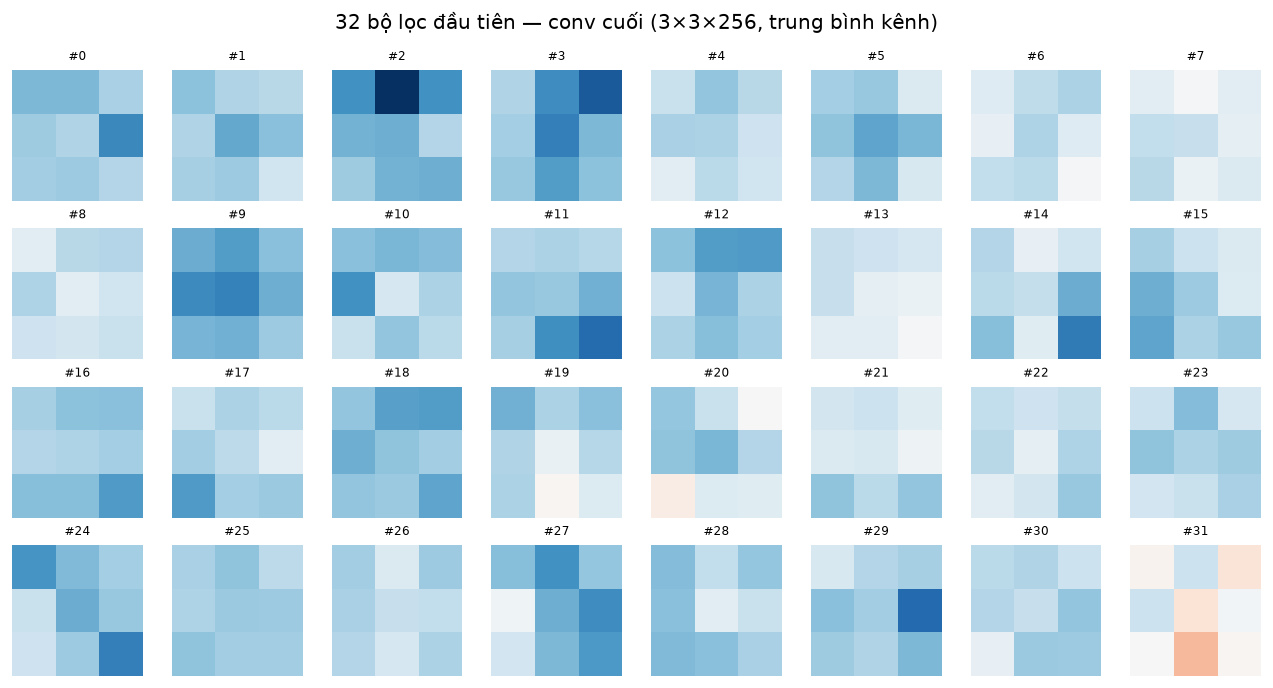

Tổng số lớp conv: 9


In [17]:
def plot_conv_filters(conv, title, fname, max_filters=32):
    weight = conv.weight.detach().float().cpu().mean(dim=1)  # (out, 3, 3)
    n = min(max_filters, weight.shape[0])
    cols = 8
    rows = math.ceil(n / cols)
    vmax = weight[:n].abs().max().item()
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.35, rows * 1.45))
    for k, ax in enumerate(np.ravel(axes)):
        ax.axis("off")
        if k < n:
            ax.imshow(weight[k], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
            ax.set_title(f"#{k}", fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG / fname, bbox_inches="tight")
    plt.show()
    plt.close(fig)


convs = [m for m in final_model.modules() if isinstance(m, nn.Conv2d)]
plot_conv_filters(convs[0], "32 bộ lọc đầu tiên — conv đầu (3×3×1)", "17_filters_conv1.png")
plot_conv_filters(convs[-1], "32 bộ lọc đầu tiên — conv cuối (3×3×256, trung bình kênh)", "18_filters_last.png")
print("Tổng số lớp conv:", len(convs))

Bộ lọc tầng đầu học các mẫu đơn giản: cạnh dọc/ngang, gradient sáng–tối, vài bộ lọc gần như phẳng (gần 0). Điều này khớp với trực giác: ở 48×48, mạng ưu tiên phát hiện đường nét khuôn mặt trước khi tổ hợp thành biểu cảm. Bộ lọc tầng cuối có biên độ lớn hơn, xen kẽ dấu dương/âm — dấu hiệu của các mẫu tổ hợp phức tạp hơn. Một số bộ lọc có năng lượng rất thấp, cho thấy mạng có thể đã dư thừa kênh; pruning nhẹ có thể là hướng tối ưu tiếp theo.

### 10.1. Feature map của một ảnh kiểm thử

Feature map cho biết mỗi bộ lọc “nhìn thấy” gì ở ảnh đầu vào. Notebook lấy một ảnh dự đoán đúng, gắn hook vào conv đầu và conv cuối, rồi hiển thị 16 kênh đầu.

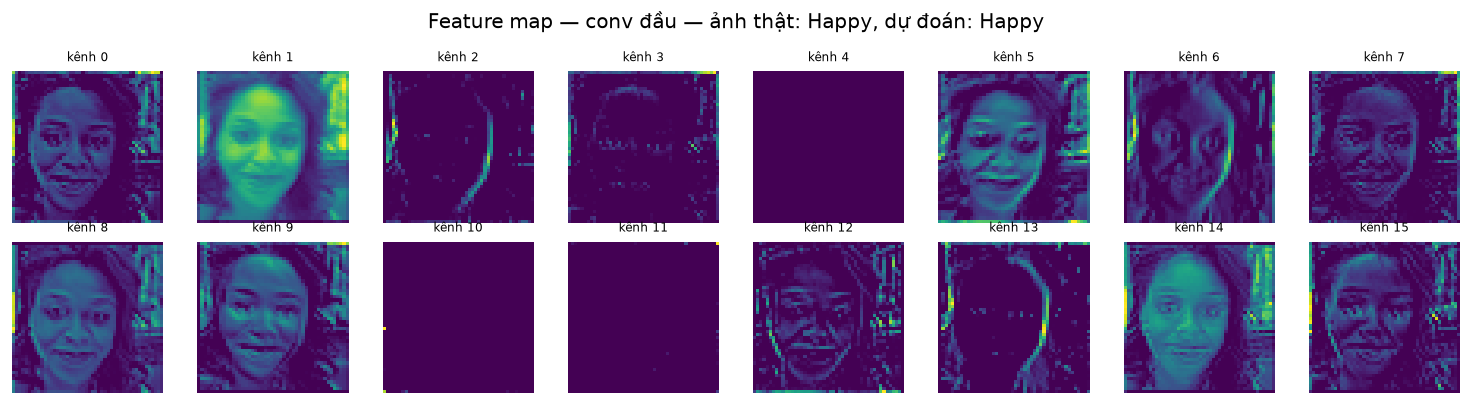

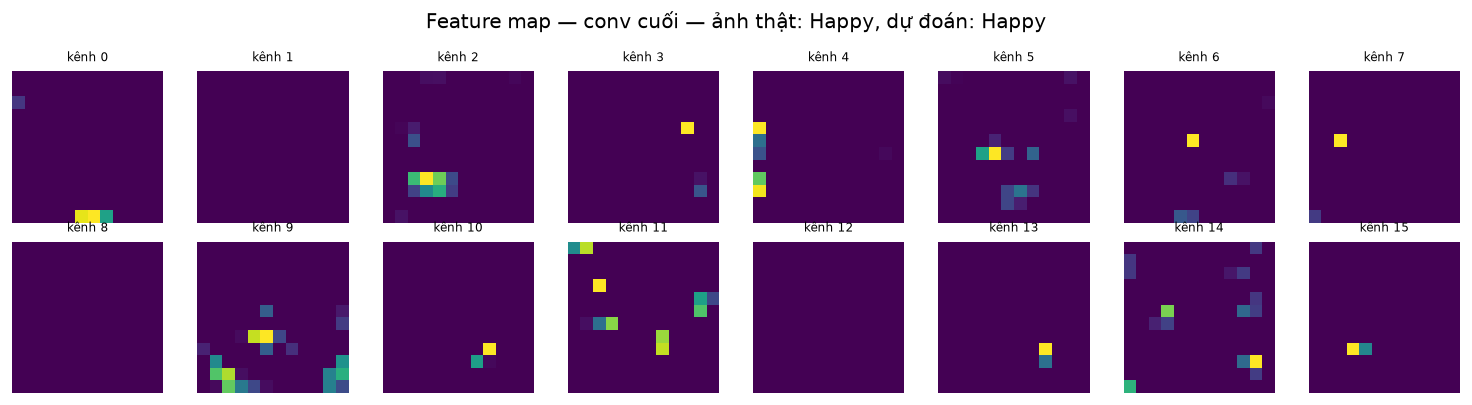

In [18]:
def get_feature_maps(model, image, max_maps=16):
    conv_layers = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
    targets = [conv_layers[0], conv_layers[-1]]
    outputs, hooks = [], []
    for layer in targets:
        hooks.append(layer.register_forward_hook(lambda m, i, o: outputs.append(o.detach())))
    model.eval()
    with torch.no_grad():
        model(image.unsqueeze(0).to(DEVICE))
    for h in hooks:
        h.remove()
    return outputs


example_i = int(rng.choice(true_idx))
maps = get_feature_maps(final_model, Xte[example_i])
for tag, fm in zip(["conv đầu", "conv cuối"], maps):
    fm = fm[0].float().cpu()
    n = min(16, fm.shape[0])
    fig, axes = plt.subplots(2, 8, figsize=(12.5, 3.4))
    for k, ax in enumerate(np.ravel(axes)):
        ax.axis("off")
        if k < n:
            ax.imshow(fm[k], cmap="viridis")
            ax.set_title(f"kênh {k}", fontsize=7)
    fig.suptitle(f"Feature map — {tag} — ảnh thật: {CLASSES[y_true[example_i]]}, "
                 f"dự đoán: {CLASSES[y_pred[example_i]]}")
    fig.tight_layout()
    fig.savefig(FIG / f"19_feature_maps_{'first' if tag == 'conv đầu' else 'last'}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 11. Kết luận

1. **Kiến trúc:** Large (2-2-2-2, 64-128-256-512) cho test accuracy cao nhất (61,46%), nhỉnh hơn Medium và Small khoảng 1,1–1,3 điểm; Medium vẫn là baseline ổn định và đơn giản.
2. **Kỹ thuật huấn luyện:** Augmentation là cải tiến rõ nhất (+2,2 điểm test); BatchNorm làm hội tụ chậm hơn trong 20 epoch và cần ngân sách dài hơn.
3. **Tối ưu:** Adam 5e-4 nhỉnh hơn 1e-3; SGD kém hơn khi thiếu schedule; LeakyReLU không ổn định (một seed phân kỳ).
4. **Mô hình cuối:** đạt **65,67%** accuracy và **61,66%** macro-F1 trên PrivateTest sau 45 epoch với cosine decay.
5. **Phân tích lỗi:** nhầm lẫn chủ yếu ở Sad/Neutral, Angry/Fear, Fear/Surprise; Disgust yếu do thiếu dữ liệu.
6. **Bộ lọc:** tầng đầu học cạnh/gradient; tầng cuối trừu tượng hơn, có kênh dư thừa.

**Hạn chế.** GPU 4 GB và thời gian có hạn nên các khảo sát chỉ chạy 20 epoch, chưa tối ưu schedule cho từng cấu hình; kết quả có dao động theo seed. Chưa thử các kỹ thuật mạnh hơn như focal loss, class-balanced sampling, hay transfer learning từ một mạng lớn.

**Hướng phát triển.** Huấn luyện lâu hơn với cosine/ReduceLROnPlateau, thêm nhiễu và biến đổi màu, dùng focal loss cho lớp hiếm, hoặc chưng cất tri thức từ mô hình lớn hơn.

## Phụ lục — Nhật ký thực nghiệm

Cell cuối sinh file `outputs/experiment_log.xlsx` gồm 7 sheet:

| Sheet | Nội dung |
|---|---|
| Tổng quan | Thời gian, thiết bị, dữ liệu, số lượt chạy, kết quả cuối |
| Chi tiết 28 lượt | Từng lượt: seed, epoch, val/test, trạng thái |
| Tổng hợp A-B-C | Trung bình ± độ lệch chuẩn theo cấu hình |
| Cấu hình | Siêu tham số chi tiết của từng lượt |
| Lịch sử chạy | Mọi lượt: OK, EARLY_STOP, CACHED, FAILED, DEBUG |
| Lịch sử phát triển | Các mốc: smoke test, lần chạy bị ngắt, điều chỉnh, hoàn tất |
| Log từng epoch | 561 dòng log của 28 lượt |

Mỗi lượt chạy được ghi ngay vào `outputs/attempts_log.csv` qua `log_attempt()`; nếu huấn luyện lỗi, `run_logged()` ghi trạng thái `FAILED` kèm thông điệp lỗi trước khi raise lại. File Excel đi kèm bài nộp để đối chiếu với báo cáo.


In [19]:
from openpyxl import Workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# =====================================================================
# Nhật ký thực nghiệm dạng Excel: 7 sheet, ghi cả lượt thành công,
# dừng sớm, dùng cache, thất bại và các mốc debug.
# =====================================================================
XLSX = OUT / "experiment_log.xlsx"
end_time = datetime.now()

ATTEMPTS_CSV = OUT / "attempts_log.csv"
attempts = pd.read_csv(ATTEMPTS_CSV) if ATTEMPTS_CSV.exists() else pd.DataFrame(ATTEMPTS)
runs = df_all.copy()
runs["config"] = runs["run_id"].str.split("_s").str[0]

TITLE_FONT = Font(bold=True, size=14, color="1F4E79")
HEADER_FONT = Font(bold=True, color="FFFFFF")
BOLD = Font(bold=True)
SUB_FILL = PatternFill("solid", fgColor="DDEBF7")
HEADER_FILL = PatternFill("solid", fgColor="1F4E79")
THIN = Side(style="thin", color="BFBFBF")
BORDER = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
STATUS_FILL = {
    "OK": PatternFill("solid", fgColor="E2EFDA"),
    "EARLY_STOP": PatternFill("solid", fgColor="FFF2CC"),
    "CACHED": PatternFill("solid", fgColor="DDEBF7"),
    "FAILED": PatternFill("solid", fgColor="F8CBAD"),
    "DEBUG": PatternFill("solid", fgColor="EDEDED"),
    "ADJUSTED": PatternFill("solid", fgColor="FCE4D6"),
}


def clean(v):
    """Chuyển kiểu numpy/pandas sang kiểu Python để openpyxl ghi được."""
    if v is None:
        return None
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return None if math.isnan(float(v)) else float(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v


def write_sheet(ws, title, headers, rows, widths=None, formats=None,
                freeze="A3", autofilter=True, status_col=None):
    ncol = len(headers)
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=ncol)
    c = ws.cell(1, 1, title)
    c.font = TITLE_FONT
    c.alignment = Alignment(vertical="center")
    ws.row_dimensions[1].height = 24
    for j, h in enumerate(headers, 1):
        c = ws.cell(2, j, h)
        c.font = HEADER_FONT
        c.fill = HEADER_FILL
        c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        c.border = BORDER
    ws.row_dimensions[2].height = 32
    for i, row in enumerate(rows, 3):
        for j, v in enumerate(row, 1):
            c = ws.cell(i, j, clean(v))
            c.border = BORDER
            c.alignment = Alignment(vertical="top", wrap_text=isinstance(v, str))
        if status_col:
            st = str(row[status_col - 1]).upper()
            if st in STATUS_FILL:
                ws.cell(i, status_col).fill = STATUS_FILL[st]
    if widths:
        for j, w in enumerate(widths, 1):
            ws.column_dimensions[get_column_letter(j)].width = w
    if formats:
        for j, fmt in formats.items():
            for i in range(3, len(rows) + 3):
                ws.cell(i, j).number_format = fmt
    if freeze:
        ws.freeze_panes = freeze
    if autofilter and rows:
        ws.auto_filter.ref = f"A2:{get_column_letter(ncol)}{len(rows) + 2}"


def pct(v):
    return None if pd.isna(v) else round(float(v) * 100, 2)


wb = Workbook()

# ---------------------------------------------------------------------
# Sheet 1 — Tổng quan
# ---------------------------------------------------------------------
ws = wb.active
ws.title = "Tổng quan"
ws.merge_cells("A1:B1")
c = ws.cell(1, 1, "NHẬT KÝ THỰC NGHIỆM — BTL02 FER2013")
c.font = TITLE_FONT
c.alignment = Alignment(vertical="center")
ws.row_dimensions[1].height = 28

row_i = 2


def section(text):
    global row_i
    ws.merge_cells(start_row=row_i, start_column=1, end_row=row_i, end_column=2)
    c = ws.cell(row_i, 1, text)
    c.font = Font(bold=True, color="1F4E79")
    c.fill = SUB_FILL
    c.border = BORDER
    row_i += 1


def kv(key, value):
    global row_i
    c = ws.cell(row_i, 1, key)
    c.font = BOLD
    c.border = BORDER
    c.alignment = Alignment(vertical="top")
    c = ws.cell(row_i, 2, value)
    c.border = BORDER
    c.alignment = Alignment(wrap_text=True, vertical="top")
    row_i += 1


counts = attempts["status"].value_counts().to_dict() if not attempts.empty else {}
section("THÔNG TIN CHUNG")
kv("Tên bài tập", "BTL02 — Nhận dạng cảm xúc khuôn mặt trên FER2013 bằng CNN")
kv("Nhóm", "SGU26 — Chuyên đề Học sâu")
kv("Sinh viên thực hiện", "Huỳnh Nhật Minh — 3123580025")
kv("Thời điểm bắt đầu", f"{START_TIME:%d/%m/%Y %H:%M:%S}")
kv("Thời điểm kết thúc", f"{end_time:%d/%m/%Y %H:%M:%S}")
kv("Tổng thời gian", f"{(end_time - START_TIME).total_seconds() / 60:.1f} phút "
                      f"({(end_time - START_TIME).total_seconds() / 3600:.1f} giờ)")
kv("Thiết bị", f"{DEVICE}" + (f" — {torch.cuda.get_device_name(0)}" if DEVICE == "cuda" else ""))
kv("PyTorch", torch.__version__)

section("DỮ LIỆU")
kv("Tệp dữ liệu", f"data/fer2013.csv ({DATA_CSV.stat().st_size / 1e6:.1f} MB)")
kv("Train / Validation / Test", f"{len(X_train):,} / {len(X_valid):,} / {len(X_test):,} ảnh")
kv("Số lớp", "7 — Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral")

section("THỰC NGHIỆM")
kv("Số lượt khảo sát", f"{int(runs['group'].isin(['A', 'B', 'C']).sum())} "
                        f"(9 cấu hình × 3 seed)")
kv("Mô hình cuối", f"{best_id} — huấn luyện lại {FINAL_EPOCHS} epoch")
kv("Tổng số dòng lịch sử chạy", len(attempts))
kv("Trạng thái các lượt chạy",
   f"OK {counts.get('OK', 0)} | EARLY_STOP {counts.get('EARLY_STOP', 0)} | "
   f"CACHED {counts.get('CACHED', 0)} | FAILED {counts.get('FAILED', 0)} | "
   f"DEBUG {counts.get('DEBUG', 0)}")
kv("Batch size", BASE_CFG["batch_size"])
kv("Epoch khảo sát", f"{BASE_CFG['epochs']} (early stopping, patience {BASE_CFG['patience']})")
kv("Epoch mô hình cuối", f"{FINAL_EPOCHS} (cosine decay, không early stopping)")
kv("Seed khảo sát", ", ".join(map(str, SEEDS)))
kv("Tiêu chí chọn mô hình",
   "Validation accuracy trung bình trên 3 seed; không dùng PrivateTest để chọn")

section("KẾT QUẢ CUỐI")
kv("Cấu hình được chọn", f"{best_id} — Medium + augmentation")
kv("Validation accuracy", f"{final_row['best_val_acc'] * 100:.2f}%")
kv("Test accuracy (PrivateTest)", f"{final_row['test_acc'] * 100:.2f}%")
kv("Macro-F1 (PrivateTest)", f"{final_row['test_macro_f1'] * 100:.2f}%")
kv("Best epoch", f"{int(final_row['best_epoch'])}/{int(final_row['epochs_run'])}")
kv("Tham số mô hình", f"{final_row['params'] / 1e6:.2f} triệu")
kv("Thời gian huấn luyện mô hình cuối", f"{final_row['time_s']:.0f} s")

section("PHÂN BỐ LỚP")
dist = pd.read_csv(OUT / "class_distribution.csv", index_col=0)
c = ws.cell(row_i, 1, "Lớp")
c.font = HEADER_FONT
c.fill = HEADER_FILL
c.border = BORDER
c = ws.cell(row_i, 2, "Train / Validation / Test")
c.font = HEADER_FONT
c.fill = HEADER_FILL
c.border = BORDER
row_i += 1
for name, r in dist.iterrows():
    c = ws.cell(row_i, 1, name)
    c.border = BORDER
    c = ws.cell(row_i, 2, f"{int(r['Train']):,} / {int(r['Validation']):,} / {int(r['Test']):,}")
    c.border = BORDER
    row_i += 1

section("GHI CHÚ")
kv("Nguồn số liệu",
   "outputs/summary_runs.csv, outputs/summary_groups.csv, outputs/class_distribution.csv, "
   "outputs/logs/ và outputs/attempts_log.csv. Không nhập tay số liệu kết quả.")
kv("Về lịch sử phát triển",
   "Sheet 'Lịch sử phát triển' ghi lại các mốc thực tế: smoke test, lần chạy bị ngắt, "
   "lần điều chỉnh mô hình cuối và lần chạy hoàn tất.")
kv("Tính tất định",
   "Kết quả có thể lệch nhỏ khi chạy lại do cuDNN không tất định; seed và quy trình giữ nguyên.")

ws.column_dimensions["A"].width = 34
ws.column_dimensions["B"].width = 92
ws.freeze_panes = "A2"

# ---------------------------------------------------------------------
# Sheet 2 — Chi tiết từng lượt
# ---------------------------------------------------------------------
status_by_run, note_by_run = {}, {}
if not attempts.empty:
    valid_ids = set(runs["run_id"])
    for _, a in attempts.iterrows():
        rid = str(a.get("run_id", ""))
        if rid in valid_ids:
            status_by_run[rid] = a.get("status", "")
            note_by_run[rid] = a.get("note", "")

detail_rows = []
for _, r in runs.iterrows():
    detail_rows.append([
        r["run_id"], r["group"], r["label"], int(r["seed"]),
        status_by_run.get(r["run_id"], ""), int(r["best_epoch"]), int(r["epochs_run"]),
        round(float(r["best_val_loss"]), 4), pct(r["best_val_acc"]), pct(r["test_acc"]),
        pct(r["test_macro_f1"]), round(float(r["params"]) / 1e6, 3),
        round(float(r["time_s"]), 1), note_by_run.get(r["run_id"], ""),
    ])
ws = wb.create_sheet("Chi tiết 28 lượt")
write_sheet(
    ws, "CHI TIẾT 28 LƯỢT CHẠY (27 khảo sát + 1 mô hình cuối)",
    ["Run", "Nhóm", "Cấu hình", "Seed", "Trạng thái", "Best epoch", "Epoch đã chạy",
     "Val loss", "Val acc (%)", "Test acc (%)", "Macro-F1 (%)", "Tham số (M)",
     "Thời gian (s)", "Ghi chú"],
    detail_rows,
    widths=[12, 7, 38, 7, 13, 11, 13, 10, 12, 12, 12, 12, 13, 48],
    formats={8: "0.0000", 9: "0.00", 10: "0.00", 11: "0.00", 12: "0.000", 13: "0.0"},
    status_col=5,
)

# ---------------------------------------------------------------------
# Sheet 3 — Tổng hợp A-B-C
# ---------------------------------------------------------------------
survey = runs[runs["group"].isin(["A", "B", "C"])].copy()
agg = (survey.groupby(["config", "label", "group"], sort=False)
       .agg(params=("params", "first"),
            val_mean=("best_val_acc", "mean"), val_std=("best_val_acc", "std"),
            test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
            f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
            epochs=("epochs_run", "mean"), time_s=("time_s", "mean"))
       .reset_index())
order = ["A1", "A2", "A3", "B1", "B2", "B3", "C1", "C2", "C3"]
agg["__o"] = agg["config"].map({k: i for i, k in enumerate(order)})
agg = agg.sort_values("__o").drop(columns="__o")
base = agg[agg["config"] == "A2"].iloc[0]

summary_rows = []
for grp in ["A", "B", "C"]:
    if grp != "A":
        summary_rows.append([
            grp, f"{grp}0", "Baseline (A2)", base["params"] / 1e6,
            pct(base["val_mean"]), None, pct(base["test_mean"]), None,
            pct(base["f1_mean"]), None, 0.0, round(base["epochs"], 1),
            round(base["time_s"], 1),
        ])
    for _, r in agg[agg["group"] == grp].iterrows():
        summary_rows.append([
            grp, r["config"], r["label"], r["params"] / 1e6,
            pct(r["val_mean"]), pct(r["val_std"]), pct(r["test_mean"]), pct(r["test_std"]),
            pct(r["f1_mean"]), pct(r["f1_std"]),
            round((r["test_mean"] - base["test_mean"]) * 100, 2),
            round(r["epochs"], 1), round(r["time_s"], 1),
        ])
ws = wb.create_sheet("Tổng hợp A-B-C")
write_sheet(
    ws, "TỔNG HỢP THEO CẤU HÌNH (trung bình ± độ lệch chuẩn trên 3 seed)",
    ["Nhóm", "Mã", "Cấu hình", "Tham số (M)", "Val acc TB (%)", "Val std",
     "Test acc TB (%)", "Test std", "Macro-F1 TB (%)", "F1 std",
     "Δ test so với baseline", "Epoch TB", "Thời gian TB (s)"],
    summary_rows,
    widths=[7, 7, 38, 12, 13, 9, 13, 9, 14, 8, 16, 10, 14],
    formats={4: "0.00", 5: "0.00", 6: "0.00", 7: "0.00", 8: "0.00",
             9: "0.00", 10: "0.00", 11: "+0.00;-0.00", 12: "0.0", 13: "0.0"},
)

# ---------------------------------------------------------------------
# Sheet 4 — Cấu hình
# ---------------------------------------------------------------------
config_rows = []
for rid, cfg in RUN_CONFIGS.items():
    sub = runs[runs["run_id"].str.startswith(rid + "_s")]
    config_rows.append([
        rid, cfg["arch"], "-".join(map(str, cfg["widths"])),
        "-".join(map(str, cfg["convs"])), cfg["fc"], cfg["optimizer"], cfg["lr"],
        cfg["dropout"], cfg["activation"], "Có" if cfg["batchnorm"] else "Không",
        "Có" if cfg["augment"] else "Không", cfg["label_smoothing"],
        "Có" if cfg["class_weight"] else "Không",
        "Có" if cfg["cosine"] else "Không", cfg["batch_size"], cfg["epochs"],
        cfg["patience"], round(float(sub["params"].iloc[0]) / 1e6, 3),
    ])
config_rows.append([
    "FINAL", FINAL_CFG["arch"], "-".join(map(str, FINAL_CFG["widths"])),
    "-".join(map(str, FINAL_CFG["convs"])), FINAL_CFG["fc"], FINAL_CFG["optimizer"],
    FINAL_CFG["lr"], FINAL_CFG["dropout"], FINAL_CFG["activation"],
    "Có" if FINAL_CFG["batchnorm"] else "Không",
    "Có" if FINAL_CFG["augment"] else "Không", FINAL_CFG["label_smoothing"],
    "Có" if FINAL_CFG["class_weight"] else "Không",
    "Có" if FINAL_CFG["cosine"] else "Không", FINAL_CFG["batch_size"],
    FINAL_EPOCHS, "không (chạy đủ)", round(float(final_row["params"]) / 1e6, 3),
])
ws = wb.create_sheet("Cấu hình")
write_sheet(
    ws, "CẤU HÌNH CHI TIẾT CỦA TỪNG LƯỢT",
    ["Run", "Kiến trúc", "Kênh", "Conv/block", "FC", "Optimizer", "LR", "Dropout",
     "Activation", "BatchNorm", "Augmentation", "Label smoothing", "Class weight",
     "Cosine", "Batch size", "Epochs", "Patience", "Tham số (M)"],
    config_rows,
    widths=[9, 10, 20, 12, 7, 10, 10, 9, 12, 11, 13, 15, 12, 9, 11, 9, 16, 12],
    formats={7: "0.0000", 8: "0.00", 12: "0.00", 18: "0.000"},
)

# ---------------------------------------------------------------------
# Sheet 5 — Lịch sử chạy (mọi lượt: OK/EARLY_STOP/CACHED/FAILED/DEBUG)
# ---------------------------------------------------------------------
run_rows = []
if not attempts.empty:
    att = attempts.copy()
    att["__t"] = pd.to_datetime(att["time"], errors="coerce")
    att = att.sort_values("__t", na_position="last")
    for _, a in att.iterrows():
        run_rows.append([
            str(a.get("time", "")), str(a.get("run_id", "")), str(a.get("group", "")),
            str(a.get("label", "")), str(a.get("status", "")), a.get("seed", ""),
            a.get("epochs", ""), "" if pd.isna(a.get("best_epoch", np.nan)) else int(a.get("best_epoch")),
            pct(a.get("best_val_acc", np.nan)), pct(a.get("test_acc", np.nan)),
            "" if pd.isna(a.get("duration_s", np.nan)) else round(float(a.get("duration_s")), 1),
            str(a.get("note", "")),
        ])
ws = wb.create_sheet("Lịch sử chạy")
write_sheet(
    ws, "LỊCH SỬ CHẠY — GHI MỌI LƯỢT, KỂ CẢ THẤT BẠI VÀ DEBUG",
    ["Thời điểm", "Run", "Nhóm", "Mô tả", "Trạng thái", "Seed", "Epoch",
     "Best epoch", "Val acc (%)", "Test acc (%)", "Thời lượng (s)", "Ghi chú"],
    run_rows,
    widths=[20, 16, 9, 38, 13, 7, 7, 10, 12, 12, 13, 56],
    formats={7: "0", 8: "0", 9: "0.00", 10: "0.00", 11: "0.0"},
    status_col=5,
)

# ---------------------------------------------------------------------
# Sheet 6 — Lịch sử phát triển
# ---------------------------------------------------------------------
dev_rows = [[d["milestone"], d["time"], d["status"], d["event"], d["action"]]
            for d in DEV_HISTORY]
ws = wb.create_sheet("Lịch sử phát triển")
write_sheet(
    ws, "LỊCH SỬ PHÁT TRIỂN — CÁC MỐC THỰC TẾ CỦA QUÁ TRÌNH LÀM BÀI",
    ["Mốc", "Thời điểm", "Trạng thái", "Diễn biến", "Bài học / hành động"],
    dev_rows,
    widths=[22, 26, 13, 72, 62],
    status_col=3,
)

# ---------------------------------------------------------------------
# Sheet 7 — Log từng epoch
# ---------------------------------------------------------------------
log_frames = []
for _, r in runs.iterrows():
    rid = r["run_id"]
    path = OUT / "logs" / f"{rid}.csv"
    if not path.exists():
        continue
    h = pd.read_csv(path)
    h.insert(0, "run_id", rid)
    h.insert(1, "group", r["group"])
    h.insert(2, "seed", int(r["seed"]))
    h.insert(3, "label", r["label"])
    log_frames.append(h)

log_all = pd.concat(log_frames, ignore_index=True) if log_frames else pd.DataFrame()
log_rows = []
for _, h in log_all.iterrows():
    log_rows.append([
        h["run_id"], h["group"], int(h["seed"]), h["label"], int(h["epoch"]),
        round(float(h["lr"]), 7), round(float(h["train_loss"]), 4),
        round(float(h["train_acc"]) * 100, 2), round(float(h["val_loss"]), 4),
        round(float(h["val_acc"]) * 100, 2), round(float(h["time_s"]), 1),
    ])
ws = wb.create_sheet("Log từng epoch")
write_sheet(
    ws, f"LOG TỪNG EPOCH — {len(log_rows)} DÒNG TỪ {len(log_frames)} LƯỢT CHẠY",
    ["Run", "Nhóm", "Seed", "Cấu hình", "Epoch", "LR", "Train loss",
     "Train acc (%)", "Val loss", "Val acc (%)", "Thời gian (s)"],
    log_rows,
    widths=[12, 7, 7, 38, 7, 12, 11, 13, 11, 12, 13],
    formats={6: "0.0000000", 7: "0.0000", 8: "0.00", 9: "0.0000", 10: "0.00", 11: "0.0"},
)

wb.save(XLSX)

print(f"Đã ghi nhật ký Excel: {XLSX}")
print("Các sheet:")
for name in wb.sheetnames:
    print(f"  - {name}")
print(f"Chi tiết: {len(runs)} lượt | Lịch sử chạy: {len(run_rows)} dòng | "
      f"Log epoch: {len(log_rows)} dòng")
print(f"Mô hình cuối: {best_id} — validation {final_row['best_val_acc']*100:.2f}%, "
      f"test {final_row['test_acc']*100:.2f}%, macro-F1 {final_row['test_macro_f1']*100:.2f}%")


Đã ghi nhật ký Excel: C:\Users\ASUS\group_sgu26_deep_learning\BTL02\outputs\experiment_log.xlsx
Các sheet:
  - Tổng quan
  - Chi tiết 28 lượt
  - Tổng hợp A-B-C
  - Cấu hình
  - Lịch sử chạy
  - Lịch sử phát triển
  - Log từng epoch
Chi tiết: 28 lượt | Lịch sử chạy: 32 dòng | Log epoch: 561 dòng
Mô hình cuối: B1 — validation 64.95%, test 65.67%, macro-F1 61.66%


## Tài liệu tham khảo

1. Goodfellow, I. et al. (2013). *Challenges in Representation Learning: A report on three machine learning contests*. ICML Workshop (FER2013).
2. Kaggle. *Challenges in Representation Learning: Facial Expression Recognition Challenge*. https://www.kaggle.com/c/challenges-in-representation-learning-facial-expression-recognition-challenge
3. LeCun, Y., Bengio, Y., Hinton, G. (2015). *Deep Learning*. Nature 521, 436–444.
4. Ioffe, S., Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*. ICML.
5. Szegedy, C. et al. (2016). *Rethinking the Inception Architecture for Computer Vision*. CVPR.
6. Paszke, A. et al. (2019). *PyTorch: An Imperative Style, High-Performance Deep Learning Library*. NeurIPS.